# Machine Learning-Assisted Optimization in High-Dimensional Complex Landscapes
## Advanced Machine Learning for Physics – Group Project

**Project description:** Finding the best solution to complex optimization problems becomes increasingly difficult as the number of variables grows. The number of possible configurations can become extremely large, making it impossible to explore all of them directly. Spin glass models provide a useful and well-defined framework for studying this type of problem. In particular, the three dimensional Edwards–Anderson (EA) model has a complex energy landscape with many competing low-energy configurations, making the search for the minimum energy particularly challenging. In this project, we use the EA model to study how different annealing based algorithms explore the configuration space and how efficiently they identify very low energy or minimum energy states.

---

### Scientific Background

The **Edwards-Anderson model** is defined on a 3D cubic lattice of $N = L^3$ Ising spins $s_i \in \{-1, +1\}$, with nearest-neighbour random couplings $J_{ij} \sim \mathcal{N}(0,1)$. The Hamiltonian is:

$$\mathcal{H} = -\frac{1}{2}\sum_{\langle i,j \rangle} J_{ij}\, s_i\, s_j$$

Finding the ground state is hard optimization problem. The difficulty arises from the exponentially large configuration space ($2^N$ states) and the presence of many local minima (metastable states) separated by large energy barriers as typical of spin glasses

---
### Project Goals

This notebook addresses three project tasks:

- **Task 1 - Reproduction:** Compare three optimization algorithms: Simulated Annealing (SA), Population Annealing (PA), and Global Annealing (GA) on the 3D EA model with $L=10$ ($N=1000$ spins), reproducing the results of the reference paper.

- **Task 2 - Sampling extension:** Extend the GA algorithm to function as an equilibrium **sampler** at finite temperature $T$, rather than purely as an optimizer. We evaluate its performance by comparing thermodynamic observables against SA and PA at the same temperature.

- **Task 3 - From the EA model to the SK model:** We executed a preliminary analysis of a different model with the 3 algorithms. Results are only a first analysis and further investigation is required.

---

### Algorithms Overview
The three algorithms explored are the following:
- SA: cool the system → local spin updates
- PA: cool the system → select and replicate good configurations → local updates
- GA: learn the population → propose global configurations → local updates → retrain

The key innovation of GA is using a **MADE** (Masked Autoencoder for Distribution Estimation) to learn the approximate Boltzmann distribution of the current population, then proposing new configurations via autoregressive sampling, accepted/rejected with a Metropolis-Hastings criterion. This allows the algorithm to escape local minima more efficiently than single-spin-flip moves.

---


### Notebook Structure

1. **Setup & Imports:** dependencies and GPU configuration  
2. **Utilities:** energy computation, temperature schedule, observables  
3. **Simulated Annealing (SA):** implementation
4. **Population Annealing (PA):**  implementation
5. **Global Annealing (GA) & MADE:** neural network architecture, training, implementation
6. **Reproducing the results (Task 1):** reproduce figure 1B from the reference paper
7. **Sampler extension (Task 2):** SA, PA, GA as equilibrium samplers at finite $T$
8. **The SK model (Task 3):** SA, PA, GA on a different model

## 0. Setup and Dependencies
**Hardware:** the code uses GPU-parallelized Monte Carlo over a population of replicas, so a GPU is strongly recommended for realistic `pop_size` (e.g. 10,000). All tensors are moved to the auto-detected `device` at runtime.

In [1]:
import os
import sys
from pathlib import Path
import re
import time
import numpy as np
import random
from copy import deepcopy
import subprocess
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import ExponentialLR  # smoother learning-rate decay than StepLR for MADE training

Import of the plotting functions required in this notebook. For clarity, these functions are defined in a separate plot.py file. When running in colab, plot.py must be placed in the progetto_ML folder.

In [68]:
try:
    import google.colab
    from google.colab import drive

    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except ModuleNotFoundError:
    pass

PLOT_MODULE_CANDIDATES = [Path.cwd(), Path("/content/drive/MyDrive/progetto_ML")]

plot_module_dir = next((p for p in PLOT_MODULE_CANDIDATES if (p / "plot.py").exists()), None)
if plot_module_dir is None:
    raise FileNotFoundError("Could not find plot.py. In Colab put it in MyDrive/progetto_ML, or run from a folder that contains plot.py.")

if str(plot_module_dir) not in sys.path:
    sys.path.insert(0, str(plot_module_dir))

from plot import (_ordered_variants, plot_acceptance_rate_retrain_effect, plot_algos_comparison, plot_energy_histogram, plot_ga_overlap_trace, plot_pq_histograms, plot_scatter_pa_vs_ga, plot_success_probability, plot_three_algos_three_panels_paper_style,plot_energy_comparison )


This block automatically prepares the data paths used throughout the project. When running on Google Colab, it clones the MLMC_optimization repository from  GitHub and reads the benchmark instances directly from its Data directory.
When running locally, it searches for an existing local copy of the same data. The helper functions below return standardized paths for coupling files,  Gurobi reference logs, and exact P(q) reference data, and also provide simple  validation checks to ensure that the required files are available before running the optimization or sampling analyses.

In [4]:
REPO_URL = "https://github.com/Laplaxe/MLMC_optimization.git"
REPO_DIR = Path("/content/MLMC_optimization")

# If running on Colab, clone the GitHub repo if it is not already present
try:
    import google.colab

    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)

    PROJECT_DIR = REPO_DIR / "Data"

except ModuleNotFoundError:
    # Local fallback: use a local clone if present
    local_candidates = [Path("MLMC_optimization/Data"), Path("../MLMC_optimization/Data"), Path("MLMC_optimization-main/Data"), Path("../MLMC_optimization-main/Data")]

    PROJECT_DIR = next((p for p in local_candidates if p.exists()), local_candidates[0])


ALPHA_DIR = PROJECT_DIR / "Alpha"
COUPLINGS_DIR = ALPHA_DIR / "Couplings"
GUROBI_LOGS_DIR = ALPHA_DIR / "gurobi_logs"
RUNS_DIR = PROJECT_DIR / "multiple_instances_L10"
PQ_DIR = PROJECT_DIR / "Omega" / "Pq"
OMEGA_SUCCESS_GA_DIR = PROJECT_DIR / "Omega" / "Success_rates" / "GA"


#checks if the files exists (as not all seeds have the same data available)
if not COUPLINGS_DIR.exists():
    raise FileNotFoundError("Expected Data/Alpha/Couplings/. " f"Checked: {COUPLINGS_DIR}")

if not GUROBI_LOGS_DIR.exists():
    print(f"[WARN] Gurobi logs directory not found: {GUROBI_LOGS_DIR}. ""Task-1 reference checks will require it, but sampler/overlap analyses can still run.")

def coupling_file(seed):
    """Return the coupling-file path for one disorder realization."""
    return COUPLINGS_DIR / f"couplings_L10_R1_seed{seed}.txt"


def gurobi_log_file(seed):
    """Return the Gurobi log path for one disorder realization."""
    return GUROBI_LOGS_DIR / f"log_{seed}.txt"


def pq_reference_files(seed, pq_dir=PQ_DIR):
    """Return the exact/reference P(q) and temperature-file paths for a seed."""
    pq_dir = Path(pq_dir)
    return (pq_dir / f"Pq_PA_{seed}_reference.npy", pq_dir / f"temperatures_PA_{seed}_reference.npy")


def validate_seed_has_couplings(seed):
    """Validate that the coupling file exists for a seed and return the seed."""
    if not coupling_file(seed).exists():
        raise FileNotFoundError(f"Seed {seed} is missing required coupling file: {coupling_file(seed)}")
    return seed


def validate_seed_has_alpha_data(seed):
    """Validate that both coupling and Gurobi reference files exist for a seed."""
    missing = []

    if not coupling_file(seed).exists():
        missing.append(str(coupling_file(seed)))

    if not gurobi_log_file(seed).exists():
        missing.append(str(gurobi_log_file(seed)))

    if missing:
        raise FileNotFoundError(f"Seed {seed} is missing required Alpha files: {missing}")

    return seed


def validate_seed_has_overlap_reference(seed, T_target=None, pq_dir=PQ_DIR):
    """Validate coupling plus exact/reference P(q) files for sampler overlap plots."""
    validate_seed_has_couplings(seed)
    pq_path, temp_path = pq_reference_files(seed, pq_dir=pq_dir)
    missing = [str(p) for p in (pq_path, temp_path) if not p.exists()]
    if missing:
        raise FileNotFoundError(f"Seed {seed} is missing required overlap-reference files: {missing}")

    if T_target is not None:
        import numpy as _np

        temperatures = _np.load(temp_path)
        idx = int(_np.argmin(_np.abs(temperatures - T_target)))
        T_found = float(temperatures[idx])
        if not _np.isclose(T_found, T_target):
            print(f"[WARN] Closest exact P(q) temperature for seed {seed} is {T_found}, requested {T_target}.")

    return seed


def validate_alpha_seed_list(seeds):
    """Validate every seed in a list against the full Alpha data layout."""
    return [validate_seed_has_alpha_data(seed) for seed in seeds]

The best available PyTorch device is selected automatically: CUDA GPU first, then MPS on Apple Silicon, otherwise CPU. The sync_device() function forces GPU synchronization before timing measurements, making the benchmarks accurate.

In [5]:
# Device configuration: CUDA GPU > Apple Silicon (MPS) > CPU
print("PyTorch version:", torch.__version__)

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("Using device: CUDA GPU ->", torch.cuda.get_device_name(0))
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Using device: Apple Silicon GPU (MPS)")
else:
    device = torch.device("cpu")
    print("Using device: CPU (no CUDA/MPS found -- this will be slow for pop_size~10000)")


def sync_device(dev=None):
    """Device-agnostic replacement for torch.cuda.synchronize(): blocks until
    all queued GPU work has finished, so that time.time() measurements taken
    right after this call are accurate. No-ops on CPU (already synchronous).
    """
    dev = dev if dev is not None else device
    if dev.type == "cuda":
        torch.cuda.synchronize()
    elif dev.type == "mps":
        torch.mps.synchronize()
    # CPU: nothing to do, all ops are already synchronous


PyTorch version: 2.11.0+cu128
Using device: CUDA GPU -> Tesla T4


These functions read the input data: read_couplings() builds the symmetric interaction matrix $J_{ij}$ from the couplings file. read_gurobi_energy() extracts the ground-state energy from the Gurobi log, which is used as the reference value.

In [6]:
# Read the coupling matrix.
def read_couplings(file, N):
    """
    Read couplings from a file and return as a symmetric torch tensor.
    File format: each row is  'i  j  J_ij'.
    """
    x=np.loadtxt(file)
    rows=x[:, 0].astype(int)
    cols=x[:, 1].astype(int)
    vals=x[:, 2]

    J=torch.zeros(N, N)
    J[rows, cols]=torch.tensor(vals, dtype=torch.float32)
    J[cols, rows]=torch.tensor(vals, dtype=torch.float32)  # symmetric coupling matrix
    return J

# Read the Gurobi reference energy.
def read_gurobi_energy(gurobi_log_path):
    """
    Extract the ground state energy from a Gurobi log file.
    Looks for a line of the form: 'Best objective <value>, ...'
    """
    with open(gurobi_log_path, "r", errors="ignore") as f:
        text=f.read()

    match=re.search(r"Best objective\s+([-+0-9.eE]+)", text)
    if match is None:
        raise ValueError(f"Could not find Gurobi energy in: {gurobi_log_path}")

    return float(match.group(1))

## 1. Core Utilities

This section contains the basic numerical tools used by all annealing algorithms implemented in the notebook: Simulated Annealing (SA), Population Annealing (PA), and Global Annealing (GA). These utilities define how energies are computed, how the temperature schedule is generated, how local Monte Carlo moves are performed, and how observables are collected during optimization or sampling.

### 1.1 Energy Function

The Edwards-Anderson energy of a single spin configuration is

$$E(s) = -\frac{1}{2}\sum_{i,j} J_{ij}s_i s_j$$

For a population of configurations, indexed by $k$, the energy of the $k$-th replica is

$$E_k = -\frac{1}{2}\sum_{i,j} J_{ij}s_{k,i}s_{k,j}$$

The factor $\frac{1}{2}$ avoids double-counting the interaction pairs $(i,j)$ and $(j,i)$, since the coupling matrix is symmetric.

Using `torch.einsum` allows us to vectorize the energy computation over the entire population. This avoids explicit Python loops over replicas and makes the operation more efficient on GPUs, where many configurations can be processed in parallel.



---

### 1.2 Temperature Schedule


The annealing algorithms use a logarithmic cooling schedule. This generates `temp_steps` temperatures between $T_{\max}$ and $T_{\min}$, uniformly spaced on a logarithmic scale.

A logarithmic schedule is useful because the relevant physical changes often occur over temperature ratios rather than absolute temperature differences. In particular, it gives a denser sampling of the low-temperature region, where the system becomes harder to equilibrate and where optimization performance is most sensitive.

In [7]:
def compute_energy(population, J):
    """
    Compute the energy for each configuration using the Edwards-Anderson (EA) energy formula.
    The function calculates the EA energy for each configuration in tensor 'population' using
    the interaction matrix 'J'.  The computed energy values are returned as a tensor.
    The energy is computed for each configuration in the population using tensor operations for efficiency.
    """
    return -(torch.einsum("ki,ik->k", population, torch.einsum("ij,kj->ik", J, population)))/2



def temperature_change(T_min, T_max, temp_steps):
    """Return a logarithmic cooling schedule from T_max down to T_min."""
    return np.logspace(np.log10(T_max), np.log10(T_min), temp_steps)


### 1.3 Checkerboard Decomposition of the 3D Lattice

The function get_indices constructs a checkerboard decomposition of the cubic lattice. Each spin is identified by three coordinates $(x,y,z)$, but for tensor operations it is more convenient to map each site to a single flattened index:  $i = xL^2 + yL + z$. The lattice is split into two sublattices according to the parity of $x+y+z$. If $(x+y+z) \% 2 = 0$, the site belongs to the even sublattice. Otherwise, it belongs to the odd sublattice.

This decomposition is useful because, for nearest-neighbor-like interactions on a bipartite lattice, all spins in one sublattice can be updated simultaneously while keeping the opposite sublattice fixed. The checkerboard update is especially convenient for GPU computation as instead of proposing and accepting one spin flip at a time, we propose many conditionally independent flips in parallel.


In [8]:
def get_indices(dim=10):
    """
    Generate even and odd indices tensors for a 3D checkerboard pattern in a dim x dim x dim cube.
    Instead of relying on 3 indeces (x,y,z) to identify the spin sites, we can use a single index that runs from 0 to dim^3-1, which is more efficient for tensor operations.
    The even and odd indices are determined by the parity of the sum of the coordinates (x+y+z).
    If the sum is even, the index is added to the even_indices list; if odd, it is added to the odd_indices list.
    Finally, these lists are converted into tensors and moved to the GPU for efficient computation.
    """

    # Store the two checkerboard sublattices separately.
    even_indices=[]
    odd_indices=[]

    # Convert 3D lattice coordinates to flat spin indices.
    for x in range(dim):
        for y in range(dim):
            for z in range(dim):
                # Flat index of the spin site.
                index = x*dim*dim + y*dim +z

                # Checkerboard parity defines independent update sets.
                if (x+y+z) % 2 == 0:
                    even_indices.append(index)
                else:
                    odd_indices.append(index)

    # Return tensors on the active torch device.
    even_indices_tensor= torch.tensor(even_indices)
    odd_indices_tensor= torch.tensor(odd_indices)

    return even_indices_tensor.to(device), odd_indices_tensor.to(device)

### 1.4 Observables tracking

The Observables class stores only the measurements that are actually used later in the notebook.

- In mode="optimizer", it records the minimum energy per spin. When a reference Gurobi energy is provided, it also records elapsed time, temperature, and the energy gap $\Delta E = E_{\min} - E_{\mathrm{Gurobi}}$.
- In mode="sampler", it records the mean energy per spin of the fixed-temperature sampler

In [9]:
EPS_ZERO=1e-7
class Observables:
    """
    Tracks the measurements needed by the optimization and sampling cells.

    mode='optimizer': stores the minimum energy per spin.
    mode='sampler'  : stores the mean energy per spin at fixed temperature.

    If gurobi_energy is provided, it also records (time, T, delta_E) for convergence plots.
    """

    VALID_MODES = {"optimizer", "sampler"}

    def __init__(self, J, N, mode="optimizer", gurobi_energy=None, limit_jump=True, best_so_far=False, eps_zero=EPS_ZERO):
        """Create an observable recorder for optimizer or sampler runs."""
        if mode not in self.VALID_MODES:
            raise ValueError(f"Invalid mode '{mode}'. Choose from {self.VALID_MODES}.")

        self.J = J
        self.N = N
        self.mode = mode
        self.gurobi_energy = gurobi_energy
        self.limit_jump = limit_jump
        self.best_so_far = best_so_far
        self.eps_zero = eps_zero  # per-spin numerical floor for delta_E
        self.t_i = None  # set externally via observ.start_timer() before the annealing loop

        if mode == "optimizer":
            self.observables = {"min_energy": []}
        else:
            self.observables = {"mean_energy_per_spin": []}

        if gurobi_energy is not None:
            self.observables["time"] = []
            self.observables["temperature"] = []
            self.observables["delta_E"] = []

    def start_timer(self):
        #Call this right after sync_device(), before the annealing loop
        sync_device()
        self.t_i = time.time()

    def update(self, population, T):
        #Measure the current population at temperature T and return energies
        energies = compute_energy(population, self.J)

        if self.mode == "optimizer":
            min_E = float(energies.min().item())
            self.observables["min_energy"].append(min_E / self.N)
        else:
            mean_E = float(energies.mean().item())
            self.observables["mean_energy_per_spin"].append(mean_E / self.N)

        if self.gurobi_energy is not None:
            self._record_trace(energies, T)

        return energies

    def _record_trace(self, energies, T):
        #Record elapsed time, temperature, and delta_E = E_min - E_GS for plots
        min_energy_now = float(energies.min().item())
        delta_E_now = min_energy_now - self.gurobi_energy

        # Suppress large jumps caused by outlier configurations during cooling
        if self.limit_jump and len(self.observables["delta_E"]) > 0:
            prev_delta_E = self.observables["delta_E"][-1]
            if prev_delta_E > 0:
                jump_up = delta_E_now > 10 * prev_delta_E
                jump_down = delta_E_now < prev_delta_E / 10
                if jump_up or jump_down:
                    delta_E_now = prev_delta_E
                    min_energy_now = prev_delta_E + self.gurobi_energy

        # Enforce monotone non-increasing delta_E (best-energy-so-far tracking).
        if self.best_so_far and len(self.observables["delta_E"]) > 0:
            prev_delta_E = self.observables["delta_E"][-1]
            if delta_E_now > prev_delta_E:
                delta_E_now = prev_delta_E

        # Anything compatible with zero within numerical precision (per-spin
        # threshold EPS_ZERO, converted to the raw/total energy scale used
        # here) is treated as exactly the ground state.
        if delta_E_now <= self.eps_zero * self.N:
            delta_E_now = 0.0

        self.observables["time"].append(time.time() - self.t_i)
        self.observables["temperature"].append(float(T))
        self.observables["delta_E"].append(delta_E_now)

    def get(self, name):
        #Return one stored observable as a NumPy array
        if name not in self.observables:
            raise ValueError(f"Observable '{name}' not found.")
        return np.array(self.observables[name])

    def __repr__(self):
        #Return a compact summary useful in notebook cells
        return f"Observables(mode={self.mode}, keys={list(self.observables.keys())})"


### 1.5 Checkerboard Monte Carlo Step

The montecarlo_step function performs one Metropolis update of the whole population using a checkerboard decomposition of the lattice. The update is split into two substeps: first all even sites are updated, then all odd sites are updated.
For each selected sublattice, the code proposes a simultaneous spin flip $s_i \rightarrow -s_i$ for every replica in the population. The energy variation associated with the flip is computed from the local field
$$h_i = \sum_j J_{ij}s_j $$

For a single spin flip, the energy difference is

$$\Delta E = 2s_i h_i$$

Hence, for a $\Delta E<0$ the move is always accepted, while for an increased energy difference the configuration is accepted if $e^{-\beta \Delta E}$ is larger than a randomly generated number

In [10]:
# Checkerboard Metropolis update.
def montecarlo_step(pop, J, T, even_indices, odd_indices):
    """Monte Carlo update model using a checkerboard pattern.
    Parameters:
        pop: population of spin configurations
        J: coupling matrix
        T: scalar temperature used in the Metropolis acceptance rule
        even_indices: tensor of indices for even (checkerboard) cells
        odd_indices: tensor of indices for odd (checkerboard) cells

    Returns:
        The updated population after one Monte Carlo step."""
    population=pop.clone() #copy of the population to avoid losing it in case of rejected moves
    pop_size, N = population.shape
    device=population.device

    # Update spins in two passes (checkerboard pattern)
    for i in [even_indices, odd_indices]:
        # Propose flips for the entire population at selected indices (first for even indices, then for odd indices)
        proposed_population = population.clone()
        proposed_population[:, i] *= -1

        # Delta E for all proposed flips, computed from the local field
        delta_E = -2* torch.einsum("ki, ki->ki",proposed_population[:, i], torch.einsum("kj, ji->ki", population, J[i, :].T))

        # Metropolis acceptance criterion for each spin
        acceptance_prob = torch.exp(- delta_E / T)
        # Random numbers for accepting/rejecting proposed flips.
        random_numbers=torch.rand(pop_size,len(i),device=device)
        accepted_flips=(delta_E<0)|(random_numbers < acceptance_prob)

        #update the population with the accepted flips
        population[:, i] = torch.where(accepted_flips, proposed_population[:, i], population[:, i])

    return population


### 1.6 Final Sampling Routine

The run_fixed_temperature_sampler function is used when an algorithm is run in mode="sampler".

After the annealing schedule has reached the final temperature, the population is evolved further at a fixed sampling temperature $T_{\mathrm{sample}}$.

This final stage is meant to collect measurements from configurations that are approximately distributed according to the thermal distribution at that temperature.

Between two consecutive measurements, the function performs a configurable sampler update. For SA and PA this means thin_steps local Metropolis sweeps. For GA it can mean local-only updates, local+global MADE proposals, or local+global proposals with periodic MADE retraining.

The function mean acceptance records the acceptance rate for global moves, later used in Task 2,.  _population_two_half_overlap calculates the overlap between two populations, as we will better illustrate in Task 2

In [11]:
GA_SAMPLER_MODES = {"local", "local_global", "local_global_retrain"}


def _mean_acceptance(acc_list):
    """Convert a list of acceptance rates to one scalar mean."""
    if acc_list is None or len(acc_list) == 0:
        return np.nan
    values = []
    for acc in acc_list:
        if torch.is_tensor(acc):
            values.append(float(acc.detach().cpu().item()))
        else:
            values.append(float(acc))
    return float(np.mean(values)) if values else np.nan


def _population_two_half_overlap(population):
    """Estimate replica overlap by pairing the two halves of a population."""
    half = population.shape[0] // 2
    if half == 0:
        return np.nan, np.nan
    q = (population[:half] * population[half:2 * half]).sum(dim=1) / population.shape[1]
    return float(q.mean().item()), float(q.std().item())


def run_fixed_temperature_sampler(population, J, L, T_sample, observ, n_samples=100, save_configs=False, sampler_algorithm="local", thin_steps=20, model=None, sampler_mode="local", sampler_local_steps=None, sampler_global_steps=1, sampler_retrain_every=None, sampler_retrain_epochs=1, batch_size=256, sampler_record_diagnostics=False, sampler_gs_energy_per_spin=None, eps_zero=EPS_ZERO):
    """
    Run the common fixed-temperature sampling phase for SA, PA and GA.

    sampler_algorithm:
      - "SA", "PA" or "local": local checkerboard Metropolis only, with
        thin_steps sweeps between recorded samples.
      - "GA": configurable local/global/retrain sampling through sampler_mode.

    Returns the updated population, optional saved populations, and the possibly
    retrained MADE model.
    """
    algorithm = sampler_algorithm.lower()
    if algorithm not in {"sa", "pa", "local", "ga"}:
        raise ValueError("sampler_algorithm must be one of 'SA', 'PA', 'local' or 'GA'.")
    if n_samples < 0:
        raise ValueError("n_samples must be non-negative.")
    if thin_steps < 0:
        raise ValueError("thin_steps must be non-negative.")

    use_ga = algorithm == "ga"
    if sampler_local_steps is None:
        sampler_local_steps = thin_steps
    if sampler_local_steps < 0:
        raise ValueError("sampler_local_steps must be non-negative.")
    if sampler_global_steps < 0:
        raise ValueError("sampler_global_steps must be non-negative.")

    if not use_ga:
        sampler_mode = "local"
        sampler_local_steps = thin_steps
        sampler_global_steps = 0
        sampler_retrain_every = None
    else:
        if sampler_mode not in GA_SAMPLER_MODES:
            raise ValueError(f"Invalid sampler_mode={sampler_mode!r}. Choose from {sorted(GA_SAMPLER_MODES)}.")
        use_global = sampler_mode in {"local_global", "local_global_retrain"}
        use_retrain = sampler_mode == "local_global_retrain"

        if not use_global:
            sampler_global_steps = 0
            sampler_retrain_every = None
        elif sampler_global_steps == 0:
            raise ValueError("sampler_global_steps must be > 0 when sampler_mode uses global moves.")
        elif n_samples > 0 and model is None:
            raise ValueError("A trained MADE model is required for GA sampler global moves.")

        if use_retrain and sampler_retrain_every is None:
            sampler_retrain_every = 50
        if use_retrain and sampler_retrain_every <= 0:
            raise ValueError("sampler_retrain_every must be positive when retraining is enabled.")
        if not use_retrain:
            sampler_retrain_every = None

    N = L * L * L
    beta = 1.0 / T_sample
    even_indices, odd_indices = get_indices(L)
    samples_list = []
    trace = {k: [] for k in ["step", "time", "min_energy_per_spin", "mean_energy_per_spin", "delta_E_best", "acc_rate", "overlap_mean", "overlap_std"]}
    best_delta = np.inf

    sync_device(population.device)
    t0 = time.time()

    for step in range(1, n_samples + 1):
        acc_list = []

        if use_ga and sampler_mode in {"local_global", "local_global_retrain"}:
            population, acc_list = MLMC_fast(model=model, data=population, beta=beta, N=N, J=J, num_steps=sampler_global_steps)

        for _ in range(sampler_local_steps):
            population = montecarlo_step(population, J, T_sample, even_indices, odd_indices)

        if use_ga and sampler_retrain_every is not None and step % sampler_retrain_every == 0:
            model = retrain_made(model, dataset=population, epochs=sampler_retrain_epochs, batch_size=batch_size)

        energies = observ.update(population, T=T_sample)

        if save_configs:
            samples_list.append(population.detach().cpu().clone())

        if sampler_record_diagnostics:
            min_E = float(energies.min().item()) / N
            mean_E = float(energies.mean().item()) / N
            q_mean, q_std = _population_two_half_overlap(population)

            trace["step"].append(step)
            trace["time"].append(time.time() - t0)
            trace["min_energy_per_spin"].append(min_E)
            trace["mean_energy_per_spin"].append(mean_E)
            trace["acc_rate"].append(_mean_acceptance(acc_list))
            trace["overlap_mean"].append(q_mean)
            trace["overlap_std"].append(q_std)

            if sampler_gs_energy_per_spin is not None:
                delta_inst = max(min_E - sampler_gs_energy_per_spin, 0.0)
                if delta_inst <= eps_zero:
                    delta_inst = 0.0
                best_delta = delta_inst if best_delta == np.inf else min(best_delta, delta_inst)
                trace["delta_E_best"].append(best_delta)

    samples = torch.stack(samples_list, dim=0) if save_configs and samples_list else None

    if sampler_record_diagnostics:
        observ.sampler_trace = {k: np.array(v) for k, v in trace.items()}
        observ.sampler_trace["sampler_algorithm"] = sampler_algorithm
        observ.sampler_trace["sampler_mode"] = sampler_mode
        observ.sampler_trace["sampler_local_steps"] = sampler_local_steps
        observ.sampler_trace["sampler_global_steps"] = sampler_global_steps
        observ.sampler_trace["sampler_retrain_every"] = sampler_retrain_every
        observ.sampler_trace["sampler_retrain_epochs"] = sampler_retrain_epochs

    return population, samples, model


### 1.7 Plotting trace data

build_trace_data converts the relevant data stored by `Observables` into a plain dictionary of NumPy arrays. The plotting functions use this dictionary to draw the optimization traces: elapsed time, current temperature, minimum energy per spin, and the gap from the reference ground-state energy.


In [12]:
def build_trace_data(observ, ground_state_tol=EPS_ZERO):
    """
    Convert the trace fields of an Observables object into a plain dict of numpy arrays,
    compatible with plot_algos_comparison / plot_three_algos_three_panels_paper_style.

    Only valid when gurobi_energy was provided (optimizer mode).

    ground_state_tol is kept only to use the same function interface as the plotting functions.
    Here we do not round Delta E to zero, because the raw energy gap depends on the system size N.
    The zero cutoff is applied later in the plotting functions, after computing the per-spin gap Delta E / N

    """
    required = ["time", "temperature", "min_energy", "delta_E"]
    for key in required:
        if key not in observ.observables:
            raise ValueError(f"build_trace_data: '{key}' not found in observables. Make sure gurobi_energy was passed and mode='optimizer'.")
    trace_data = {key: observ.get(key) for key in required}
    trace_data["delta_E"] = np.asarray(trace_data["delta_E"], dtype=float)
    return trace_data


## 2. Simulated Annealing (SA)

Simulated Annealing is used as the baseline optimization algorithm. The method starts from a random population of spin configurations at a high temperature $T_{\max}$. The population is then progressively cooled down to $T_{\min}$ following the logarithmic temperature schedule defined above.

At each temperature, the system is evolved through a fixed number of Monte Carlo sweeps using the checkerboard Metropolis update. At high temperature, energetically unfavorable moves can still be accepted  allowing the system to explore the configuration space. As the temperature is lowered, these moves become less likely, and the dynamics progressively focuses on lower-energy regions of the landscape.

The basic structure of the algorithm is:

1. initialize a random population of spin configurations
2. thermalize the population at $T_{\max}$
3. start the runtime counter
4. for each temperature in the cooling schedule:
   * perform mc_steps checkerboard Monte Carlo updates
   * record the relevant observables
   * stop if the time limit is reached
5. if mode="sampler", perform an additional fixed-temperature sampling stage after annealing

In optimizer mode, the algorithm records the minimum energy per spin at each temperature. If a reference Gurobi energy is provided, it also records the energy gap  $\Delta E = E_{\min} - E_{\mathrm{Gurobi}}$.

In sampler mode, the same annealing schedule is used to bring the population to the final temperature. Then, run_fixed_temperature_sampler continues the dynamics at fixed temperature and collects thermodynamic measurements or configurations.

The final sampling temperature is stored as $T_{sample} = oldT$, where oldT is the last temperature reached by the annealing loop. If the full schedule is completed, this is simply $T_{\min}$. If the algorithm stops earlier because of time_limit, then sampling is performed at the last temperature actually reached.


In [13]:
def simulated_annealing(L, J, T_min, T_max, temp_steps, pop_size, high_thermalisation_steps, mc_steps, mode="optimizer", gurobi_energy=None, limit_jump=True, best_so_far=False, time_limit=np.inf, n_samples=100, save_configs=False, thin_steps=20):
    """
    Run SA from T_max to T_min, then optionally sample locally at fixed T.

    In sampler mode the final fixed-temperature stage starts only after the
    annealing schedule has reached the last temperature actually visited;
    thin_steps controls local sweeps between recorded samples.
    """
    N = L * L * L
    even_indices, odd_indices = get_indices(L)
    temperatures = temperature_change(T_min, T_max, temp_steps)
    population = torch.randint(0, 2, (pop_size, N), device=J.device).float() * 2 - 1

    observ = Observables(J, N, mode=mode, gurobi_energy=gurobi_energy, limit_jump=limit_jump, best_so_far=best_so_far)

    oldT = temperatures[0]
    for _ in range(high_thermalisation_steps):
        population = montecarlo_step(population, J, temperatures[0], even_indices, odd_indices)


    observ.start_timer()
    observ.update(population, T=temperatures[0])

    for T in temperatures[1:]:
        if time.time() - observ.t_i >= time_limit:
            break
        for _ in range(mc_steps):
            population = montecarlo_step(population, J, T, even_indices, odd_indices)
        observ.update(population, T=T)
        oldT = T
    # Final sampling phase
    samples = None
    if mode == "sampler":
        population, samples, _ = run_fixed_temperature_sampler(population=population, J=J, L=L, T_sample=oldT, observ=observ, n_samples=n_samples, save_configs=save_configs, sampler_algorithm="SA", thin_steps=thin_steps)

    return temperatures, observ, population, samples

## 3. Population Annealing (PA)

Population Annealing extends Simulated Annealing by evolving an entire population of replicas and adding a resampling step when the temperature is lowered. As in SA, the system starts from a random population at high temperature $T_{\max}$, is first thermalized, and is then cooled down to $T_{\min}$ following the logarithmic temperature schedule.

The main difference from SA is that, at each temperature step, replicas are reweighted according to their Boltzmann weights before the Monte Carlo updates are performed. This allows lower energy replicas to be duplicated and higher-energy replicas to be discarded, while keeping the total population size fixed.

Suppose the temperature is changed from $T$ to $T'$, with $\beta = \frac{1}{T}$ and $\beta' = \frac{1}{T'}$. For each replica $k$, the resampling weight is
$$w_k \propto \exp[-(\beta' - \beta)E_k]$$

Since the annealing schedule is decreasing in temperature, one has $T' < T$, and therefore $\beta' - \beta > 0$. This means that lower-energy configurations receive larger statistical weight when the system is cooled. The probabilities are then computed using a softmax.

After the resampling step, the population is evolved at the new temperature using mc_steps checkerboard Monte Carlo sweeps, the observables are then recorded.
This produces the same type of output as Simulated Annealing, but with the additional population resampling mechanism.

In mode="optimizer", Population Annealing tracks the minimum energy per spin and, if a reference Gurobi energy is provided, the energy gap is determined.
In mode="sampler", after the annealing schedule ends, the function calls run_fixed_temperature_sampler and performs additional measurements at the final reached temperature. As in the SA implementation, if the time limit is reached before the schedule is completed, sampling is performed at the last temperature reached by the algorithm.


In [14]:
def population_annealing(L, J, T_min, T_max, temp_steps, pop_size, high_thermalisation_steps, mc_steps, mode="optimizer", gurobi_energy=None, limit_jump=True, best_so_far=False, time_limit=np.inf, n_samples=100, save_configs=False, thin_steps=20):
    """
    Run PA with resampling during cooling, then optionally sample locally.

    In sampler mode the final sampling stage is local Metropolis dynamics at
    the last temperature reached by the annealing schedule; thin_steps controls
    local sweeps between recorded samples.
    """
    N = L * L * L
    even_indices, odd_indices = get_indices(L)
    temperatures = temperature_change(T_min, T_max, temp_steps)
    population = torch.randint(0, 2, (pop_size, N), device=J.device).float() * 2 - 1

    observ = Observables(J, N, mode=mode, gurobi_energy=gurobi_energy, limit_jump=limit_jump, best_so_far=best_so_far)

    oldT = temperatures[0]
    # Thermalization at the highest temperature.
    for _ in range(high_thermalisation_steps):
        population = montecarlo_step(population, J, oldT, even_indices, odd_indices)

    observ.start_timer()
    observ.update(population, T=oldT)

    for T in temperatures[1:]:
        if time.time() - observ.t_i >= time_limit:
            break

        # Population-annealing resampling step.
        DeltaB = 1 / T - 1 / oldT
        energies = compute_energy(population, J)
        shifted_energies = energies - energies.min()
        probabilities = torch.softmax(-shifted_energies * DeltaB, dim=0)

        resampled_indices = torch.multinomial(probabilities, num_samples=pop_size, replacement=True)

        population = population[resampled_indices]

        # Local Monte Carlo updates at the new temperature.
        for _ in range(mc_steps):
            population = montecarlo_step(population, J, T, even_indices, odd_indices)

        observ.update(population, T=T)

        oldT = T

    # Final sampling phase
    samples = None
    if mode == "sampler":
        population, samples, _ = run_fixed_temperature_sampler(population=population, J=J, L=L, T_sample=oldT, observ=observ, n_samples=n_samples, save_configs=save_configs, sampler_algorithm="PA", thin_steps=thin_steps)

    return temperatures, observ, population, samples

## 4. Global Annealing (GA)

Global Annealing combines Monte Carlo sampling with a neural-network proposal distribution. The goal is to improve over purely local annealing methods by proposing global spin configurations that are learned from the current population.

As in Simulated Annealing and Population Annealing, the algorithm starts from a random population of spin configurations at high temperature $T_{\max}$. The population is first thermalized using local checkerboard Monte Carlo moves. Then, a neural autoregressive model is trained on this population. The model learns an approximate probability distribution over spin configurations and is used to generate new global proposals during the annealing process.

The key idea is that, instead of only proposing local single-spin flips, GA also proposes entire configurations generated by the neural model. These global proposals are accepted or rejected using a Metropolis-Hastings correction, so that the sampling remains statistically controlled even if the neural proposal distribution is imperfect.

At each annealing temperature, the algorithm performs three main operations:

1. generate global proposals using the autoregressive model
2. accept or reject them using a Metropolis-Hastings rule
3. perform additional local Monte Carlo sweeps to improve equilibration

After this, the autoregressive model is retrained on the updated population, so that it progressively adapts to the lower-temperature distribution.

In mode="optimizer", the algorithm tracks the minimum energy, runtime, temperature, and the gap from the reference Gurobi energy.

In mode="sampler", after the annealing schedule ends, global_annealing delegates the fixed-temperature stage to the shared run_fixed_temperature_sampler function. The GA branch can run local-only updates, local+global updates with a frozen MADE model, or local+global updates with periodic retraining. The relevant controls are sampler_mode, sampler_local_steps, sampler_global_steps, sampler_retrain_every, and sampler_retrain_epochs.


### 4.1 Autoregressive MADE Proposal Model

The neural component of Global Annealing is an autoregressive model inspired by MADE (Masked Autoencoder for Distribution Estimation). Its purpose is to learn a probability distribution over spin configurations and generate new candidate configurations for the Metropolis-Hastings step.

A spin configuration is written as $s = (s_0, s_1, \dots, s_{N-1})$ with $s_i \in \{1,-1\}$

The autoregressive factorization writes the probability of the full configuration as

$$q(s)=q(s_0) q(s_1 \mid s_0) q(s_2 \mid s_0,s_1) \cdots q(s_{N-1} \mid s_0,\dots,s_{N-2})$$

In other words, the probability of spin $s_n$ depends only on the previously generated spins.

---

**Autoregressive Masking**

The class AutoregressiveMasking enforces the autoregressive structure by applying a lower-triangular mask to the linear layer of the model. The diagonal and upper-triangular parts of the weight matrix are set to zero. This guarantees that output $n$ cannot depend on input $n$ or on any future spin $n+1,n+2,\dots$. Therefore, when the model predicts the probability of spin $s_n$, it only uses spins $ s_0,\dots,s_{n-1} $. After each optimizer update, the mask is reapplied to ensure that forbidden connections remain zero and cannot be introduced by gradient descent.

---

**MADE Network**

The MADE model is a simple autoregressive neural network with a single linear layer and a sigmoid activation. For each spin $s_n$, it outputs a probability

$$p_n = P(s_n = +1 \mid s_0,\dots,s_{n-1})$$

The sigmoid maps the network output to the interval $[0,1]$, making it interpretable as a Bernoulli probability.

The forward method computes all conditional probabilities for a batch of configurations, while forward_n computes only the probability required to generate the $n$-th spin during autoregressive sampling. Both methods are needed because forward is used during training, when the full configuration is already known, whereas forward_n is used during generation, when the configuration is built one spin at a time.

In [ ]:
class AutoregressiveMasking(object):
    """
    This class implements a masking function that can be applied to the weight matrices of a neural network to enforce an autoregressive structure.
    The mask is a lower triangular matrix that zeros out the weights corresponding to connections that would violate the autoregressive property.
    The frequency parameter controls how often the mask is reapplied during the optimization process, allowing for dynamic enforcement of the autoregressive constraint as the model learns.
    """
    def __init__(self, frequency=1):
        """Store how often the autoregressive mask should be re-applied."""
        self.frequency=frequency
        self.step_count=0

    def __call__(self, module):
        """Apply a strictly lower-triangular mask to linear-layer weights."""
        if hasattr(module, "weight"):
            self.step_count += 1

            if self.step_count % self.frequency == 0:
                with torch.no_grad():
                    module.weight.data = torch.tril(module.weight.data, diagonal=-1)

class MADE(nn.Module):
    """
    Autoregressive MADE: a single linear layer without bias with a lower triangular weight matrix. The output at position n depends only on the previous inputs 0..n-1.
    """
    def __init__(self, input_size):
        """Build a one-layer autoregressive Bernoulli model for N spins."""
        super(MADE, self).__init__()
        self.layer=nn.Linear(input_size, input_size, bias=False)
        self.activation=nn.Sigmoid()

    def forward(self, x):
        """Return all conditional spin-up probabilities for a batch (eg. p(s1), p(s2|s1),..., p(sN|s1,...,sN-1))"""
        x=self.layer(x)
        x=self.activation(2*x)

        return x

    def forward_n(self, x, n):
        """Return the conditional probability for spin n during generation (eg. p(sn|s1,...,s(n-1))"""
        nth_row = self.layer.weight[n]
        out = torch.einsum("ij,j->i", x[:, :n], nth_row[:n])
        out = self.activation(2*out)

        return out

**Training the MADE Model**

The model is trained on the current spin population. Since spins are represented as $(-1,+1)$, while binary cross entropy requires targets in $[0,1]$, the target configuration is transformed as

$$s_i = -1 \rightarrow 0 \qquad s_i = +1 \rightarrow 1$$
MADE builds the probability of a configuration spin by spin, so the total binary cross-entropy is equal to the negative log-likelihood, which is nothing but $-\log q_\mathcal{W}(s)$, where $q_\mathcal{W}(s)$ is the probability assigned by the MADE model to configuration $s$ and $\mathcal{W}$ are the weights determined by the MADE. Minimizing this loss trains the model to assign high probability to configurations similar to those in the current population.

The function train_made trains a new MADE model from scratch at the beginning of the GA procedure, while retrain_made updates the already trained model during the temperature schedule. This allows the proposal distribution to adapt as the population moves toward lower energy regions.


In [16]:
def train_made(dataset, input_size, epochs=50, batch_size=256, patience=10, learning_rate=0.001, scheduler_time=10):
    """
    Trains MADE from scratch with early stopping and exponential LR decay.
    """
    data = dataset.detach()
    model = MADE(input_size).to(data.device)
    model.train()
    clipper = AutoregressiveMasking()
    model.apply(clipper)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.BCELoss(reduction="sum")
    scheduler = ExponentialLR(optimizer, gamma=0.5)

    best_loss = float("inf")
    epochs_no_improve = 0
    best_weights = deepcopy(model.state_dict())

    n_batches = len(data) // batch_size

    if n_batches == 0:
        raise ValueError("batch_size is larger than the dataset size.")

    for epoch in range(epochs):

        total_loss = 0.0

        for _ in range(n_batches):

            indices = torch.randint(low=0, high=data.shape[0], size=(batch_size,), device=data.device)

            batch_data = data[indices]

            output = model(batch_data)
            target = (batch_data + 1) / 2  # map spins from {-1, 1} to {0, 1} for BCE
            loss = criterion(output, target)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            model.apply(clipper)

            total_loss += loss.item()

        if (epoch + 1) % scheduler_time == 0:
            scheduler.step()

        epoch_loss = total_loss / n_batches

        if epoch_loss < best_loss:
            best_loss = epoch_loss
            epochs_no_improve = 0
            best_weights = deepcopy(model.state_dict())
        else:
            epochs_no_improve += 1

        if epochs_no_improve >= patience:
            break

    model.load_state_dict(best_weights)

    return model

In [17]:
def retrain_made(model, dataset, epochs=50, batch_size=256, learning_rate=0.001):
    """
    Retrains an already trained MADE.
    """

    data = dataset.detach()

    model.train()

    clipper = AutoregressiveMasking()
    model.apply(clipper)

    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.BCELoss(reduction="sum")

    n_batches = len(data) // batch_size

    if n_batches == 0:
        raise ValueError("batch_size is larger than the dataset size.")

    for _ in range(epochs):

        for _ in range(n_batches):

            indices = torch.randint(low=0, high=data.shape[0], size=(batch_size,), device=data.device)

            batch_data = data[indices]

            output = model(batch_data)
            target = (batch_data + 1) / 2

            loss = criterion(output, target)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            model.apply(clipper)

    return model

### 4.2 Global Proposals, MLMC Moves, and the GA Loop

Once the MADE model has been trained, it can be used to generate new spin configurations. This is done by the function generate_config. The generation is autoregressive: the configuration is built one spin at a time. At step $n$, the model computes $p(s_n = +1 \mid s_0,\dots,s_{n-1})$ then samples the spin from a Bernoulli distribution. A Bernoulli distribution is used because each spin has only two possible values, $s_n=\pm 1$, so a simple discrete probability is enough to describe the sampling process. However note that the binary values of the said distribution are $[0,1]$ and hence the result is then mapped back to the spin representation $[-1,+1]$.

This produces a full batch of proposed configurations, $q_\mathcal{W}(s)$, where $q_\mathcal{W}$ is the learned MADE proposal distribution.


In [18]:
def generate_config(model, N_spins, N_config, device):
    """
    Generates N_config spin configurations autoregressively using MADE.
    """
    model.eval()
    with torch.no_grad():

        config = torch.zeros((N_config, N_spins), device=device)

        for n in range(N_spins):

            probs = model.forward_n(config, n)

            config[:, n] = torch.bernoulli(probs) * 2 - 1

    return config


**Metropolis-Hastings Correction**

Since the MADE model does not generate configurations uniformly, the proposal probability must be included in the acceptance rule. The target distribution at inverse temperature $\beta = \frac{1}{T}$ is the Boltzmann distribution $\pi(s) \propto e^{-\beta E(s)}$.
Given a current configuration $s$ and a proposed configuration $s'$, the Metropolis-Hastings acceptance ratio is $$A(s \to s')=\frac{\pi(s')q_\mathcal{W}(s)}{\pi(s)q_\mathcal{W}(s')}.$$

Taking the logarithm gives

$$\log A=-\beta E(s') +\beta E(s) +\log q_\mathcal{W}(s)-\log q_\mathcal{W}(s')$$

As mentioned the MADE loss gives the negative log-probability:

$$\mathrm{BCE}(s) = -\log q_\mathcal{W}(s)$$

Therefore,

$$\log A=-\beta E(s') +\beta E(s)+\mathrm{BCE}(s')-\mathrm{BCE}(s)$$

This is the quantity computed inside MLMC_fast. A proposed configuration is accepted when

$$\log r < \log A$$

where $r$ is a random number uniformly sampled in $[0,1]$.


**Local Monte Carlo Moves**

After the global MADE proposals, the algorithm also performs standard checkerboard Monte Carlo updates. These local moves help the population equilibrate at the current temperature and compensate for imperfections in the learned proposal model. In practice, the global moves help explore distant regions of configuration space, while the local moves refine the configurations according to the physical energy landscape.

In [19]:
def MLMC_fast(model, data, beta, N, J, num_steps=10):
    """
    Metropolis-Hastings with proposals generated by MADE.
    """

    acc_rates = [] #acceptance rates for each step

    model.eval()

    with torch.no_grad():

        bce = nn.BCELoss(reduction="none")

        #save the current configuration is the new one is rejected
        current_config = data.clone()

        for _ in range(num_steps):

            #I generate the new configurations using the MADE model, which will be used as proposals in the Metropolis-Hastings algorithm.
            new_config = generate_config(model=model, N_spins=N, N_config=len(data), device=data.device)

            #we determine the acceptance ratio
            current_energy = compute_energy(current_config, J)
            new_energy = compute_energy(new_config, J)

            current_bce = torch.sum(bce(model(current_config), (current_config + 1) / 2), dim=1)
            new_bce = torch.sum(bce(model(new_config), (new_config + 1) / 2), dim=1)

            log_acceptance_ratio = (-beta * new_energy + new_bce + beta * current_energy - current_bce)

            random_logs = torch.log(torch.rand(size=(len(data),), device=data.device))

            acceptances = random_logs < log_acceptance_ratio

            current_config = torch.where(acceptances[:, None], new_config, current_config)

            acc_rates.append(float(acceptances.float().mean().item()))

    return current_config, acc_rates


### 4.3 Full Global Annealing Loop

The global_annealing function combines all previous components.

First, a random population is initialized and thermalized at $T_{\max}$. Then, a MADE model is trained on this initial thermalized population. During the annealing schedule, each temperature step consists of:

1. several MADE-based global Metropolis-Hastings moves
2. several local checkerboard Monte Carlo sweeps
3. retraining of the MADE model on the updated population
4. observable recording.


The model is therefore continuously adapted to the distribution explored by the population. At high temperatures, the model learns broad, disordered configurations. At low temperatures, it learns a distribution increasingly concentrated around low energy states.
The model can be used in two modes as for SA and PA.

In [20]:
def _copy_model_to_device(model, device):
    """Deep-copy a model and move it to the target device."""
    if model is None:
        return None
    return deepcopy(model).to(device)


def global_annealing(L, J, pop_size, MLMC_steps, swap_step, T_min, T_max, temp_steps, mode="optimizer", gurobi_energy=None, limit_jump=True, best_so_far=False, high_thermalisation_steps=200, batch_size=256, num_epochs_start=40, num_epochs_retrain=1, time_limit=np.inf, n_samples=100, save_configs=False, sampler_mode="local", sampler_local_steps=20, sampler_global_steps=1, sampler_retrain_every=None, sampler_retrain_epochs=None, sampler_record_diagnostics=False, sampler_gs_energy_per_spin=None, initial_population=None, initial_model=None, skip_annealing=False):
    """
    Global Annealing with MADE + MLMC.

    mode='optimizer':
        Tracks min_energy, delta_E, time, temperature.

    mode='sampler':
        Runs the annealing schedule, then performs a configurable fixed-T
        sampler stage. The sampler can be local-only, local+global with frozen
        MADE, or local+global with periodic MADE retraining.
    """

    #skip annealing is later required in Task 2. Note that the initial population (already annealed) and model must be provided in this case, otherwise the algorithm will not work.
    #This just allows to run the fixed temperature sampler starting from a the same annealed population and model, without running the annealing schedule again.
    if skip_annealing and mode != "sampler":
        raise ValueError("skip_annealing=True is only supported with mode='sampler'.")

    N = L * L * L
    even_indices, odd_indices = get_indices(L)
    temperatures = temperature_change(T_min, T_max, temp_steps)

    # Initialize the population either randomly or from a provided initial population.
    if initial_population is None:
        population = torch.randint(0, 2, (pop_size, N), device=J.device).float() * 2 - 1
    else:
        population = initial_population.detach().clone().to(J.device)
        if population.shape[1] != N:
            raise ValueError(f"initial_population has N={population.shape[1]}, expected {N}.")
        pop_size = population.shape[0]

    observ = Observables(J, N, mode=mode, gurobi_energy=gurobi_energy, limit_jump=limit_jump, best_so_far=best_so_far)

    oldT = temperatures[0]
    model = _copy_model_to_device(initial_model, J.device)

    if not skip_annealing:
        # High-temperature thermalization
        for _ in range(high_thermalisation_steps):
            population = montecarlo_step(population, J, oldT, even_indices, odd_indices)

    observ.start_timer()

    if not skip_annealing:
        observ.update(population, T=oldT)

        if model is None:
            model = train_made(dataset=population, input_size=N, epochs=num_epochs_start, batch_size=batch_size)

        # Annealing loop
        for currT in temperatures[1:]:

            if time.time() - observ.t_i >= time_limit:
                break

            beta = 1 / currT

            for _ in range(MLMC_steps):
                population, _ = MLMC_fast(model=model, data=population, beta=beta, N=N, J=J, num_steps=1)

                for _ in range(swap_step):
                    population = montecarlo_step(population, J, currT, even_indices, odd_indices)

            model = retrain_made(model=model, dataset=population, epochs=num_epochs_retrain, batch_size=batch_size)

            observ.update(population, T=currT)
            oldT = currT

    samples = None

    if mode == "sampler":
        T_sample = oldT if not skip_annealing else T_min
        if sampler_retrain_epochs is None:
            sampler_retrain_epochs = num_epochs_retrain

        needs_sampler_model = sampler_mode in {"local_global", "local_global_retrain"} and n_samples > 0
        if model is None and needs_sampler_model:
            model = train_made(dataset=population, input_size=N, epochs=num_epochs_start, batch_size=batch_size)

        population, samples, model = run_fixed_temperature_sampler(population=population, model=model, J=J, L=L, T_sample=T_sample, observ=observ, n_samples=n_samples, save_configs=save_configs, sampler_algorithm="GA", sampler_mode=sampler_mode, sampler_local_steps=sampler_local_steps, sampler_global_steps=sampler_global_steps, sampler_retrain_every=sampler_retrain_every, sampler_retrain_epochs=sampler_retrain_epochs, batch_size=batch_size, sampler_record_diagnostics=sampler_record_diagnostics, sampler_gs_energy_per_spin=sampler_gs_energy_per_spin, eps_zero=EPS_ZERO)

    return temperatures, observ, population, samples, model


# Task 1: Reproducing the paper plots

The following cells run SA, PA, and GA on one seed, collect the convergence traces, and reproduce the main algorithm comparison plot.


 ### Parameters

These values define the lattice size, annealing schedules, population size and reference-energy settings used by the Task-1 runs.


In [35]:
L = 10
N = L**3

T_max = 1.92
T_min = 0.1
temp_steps_SA = 30
temp_steps_PA = 30
temp_steps_GA = 55
pop_size = 10000
high_thermalisation_steps = 200
mc_steps = 320

seed = validate_seed_has_alpha_data(1051560)

limit_jump = False
best_so_far = False
GROUND_STATE_TOL = 1e-7# Delta E/N values <= 1e-7 are rounded to zero in plots

# GA specific parameters
MLMC_steps = 5
swap_step = 15

batch_size = 256
num_epochs_start = 40
num_epochs_retrain = 1

# Reproducibility
torch.manual_seed(seed)
np.random.seed(seed % (2**32 - 1))
random.seed(seed)

print("Using device:", device)

#input files for couplings and Gurobi logs
coupling_path = coupling_file(seed)
gurobi_log_path = gurobi_log_file(seed)

J = read_couplings(coupling_path, N).to(device)
gurobi_energy = read_gurobi_energy(gurobi_log_path)

print("Gurobi energy:", gurobi_energy)
print("Gurobi energy per spin:", gurobi_energy / N)

Using device: cuda
Gurobi energy: -1639.194274599
Gurobi energy per spin: -1.639194274599


## Reproducing Fig. 1 of the paper

Each algorithm is run once with the same physical instance. The output dictionaries store the final population and the trace data needed by plot_algos_comparison


In [36]:
#SA
print("Running Simulated Annealing")
print("=" * 70)

temperatures_SA, observ_SA, population_SA, samples_SA = simulated_annealing(L=L, J=J, T_min=T_min, T_max=T_max, temp_steps=temp_steps_SA, pop_size=pop_size, high_thermalisation_steps=high_thermalisation_steps, mc_steps=mc_steps, mode="optimizer", gurobi_energy=gurobi_energy, limit_jump=limit_jump, best_so_far=best_so_far, n_samples=0, save_configs=False)
trace_data_SA = build_trace_data(observ_SA)
results_SA = {"temperatures": temperatures_SA, "observ": observ_SA, "population": population_SA, "samples": samples_SA, "trace_data": trace_data_SA}

print("SA recorded points:", len(trace_data_SA["time"]))
print("SA final Delta E / N:", trace_data_SA["delta_E"][-1] / N)
print("SA total runtime (s):", trace_data_SA["time"][-1])


#PA
print("\n")
print("Running Population Annealing")
print("=" * 70)

temperatures_PA, observ_PA, population_PA, samples_PA = population_annealing(L=L, J=J, T_min=T_min, T_max=T_max, temp_steps=temp_steps_PA, pop_size=pop_size, high_thermalisation_steps=high_thermalisation_steps, mc_steps=mc_steps, mode="optimizer", gurobi_energy=gurobi_energy, limit_jump=limit_jump, best_so_far=best_so_far, n_samples=0, save_configs=False)
trace_data_PA = build_trace_data(observ_PA)
results_PA = {"temperatures": temperatures_PA, "observ": observ_PA, "population": population_PA, "samples": samples_PA, "trace_data": trace_data_PA}

print("PA recorded points:", len(trace_data_PA["time"]))
print("PA final Delta E / N:", trace_data_PA["delta_E"][-1] / N)
print("PA total runtime (s):", trace_data_PA["time"][-1])


#GA
print("\n")
print("Running Global Annealing")
print("=" * 70)

temperatures_GA, observ_GA, population_GA, samples_GA, model_GA = global_annealing(L=L, J=J, pop_size=pop_size, MLMC_steps=MLMC_steps, swap_step=swap_step, T_min=T_min, T_max=T_max, temp_steps=temp_steps_GA, mode="optimizer", gurobi_energy=gurobi_energy, limit_jump=limit_jump,  best_so_far=best_so_far, high_thermalisation_steps=high_thermalisation_steps, batch_size=batch_size, num_epochs_start=num_epochs_start, num_epochs_retrain=num_epochs_retrain, n_samples=0, save_configs=False)
trace_data_GA = build_trace_data(observ_GA)
results_GA = {"temperatures": temperatures_GA, "observ": observ_GA, "population": population_GA, "samples": samples_GA, "model": model_GA, "trace_data": trace_data_GA}

print("GA recorded points:", len(trace_data_GA["time"]))
print("GA final Delta E / N:", trace_data_GA["delta_E"][-1] / N)
print("GA total runtime (s):", trace_data_GA["time"][-1])


Running Simulated Annealing
SA recorded points: 30
SA final Delta E / N: 0.0012982785052499822
SA total runtime (s): 117.34942674636841


Running Population Annealing
PA recorded points: 30
PA final Delta E / N: 1.8280212498211768e-07
PA total runtime (s): 116.89094471931458


Running Global Annealing
GA recorded points: 55
GA final Delta E / N: 1.8280212498211768e-07
GA total runtime (s): 112.28994131088257


Plot saved to: fig1b_replica.png


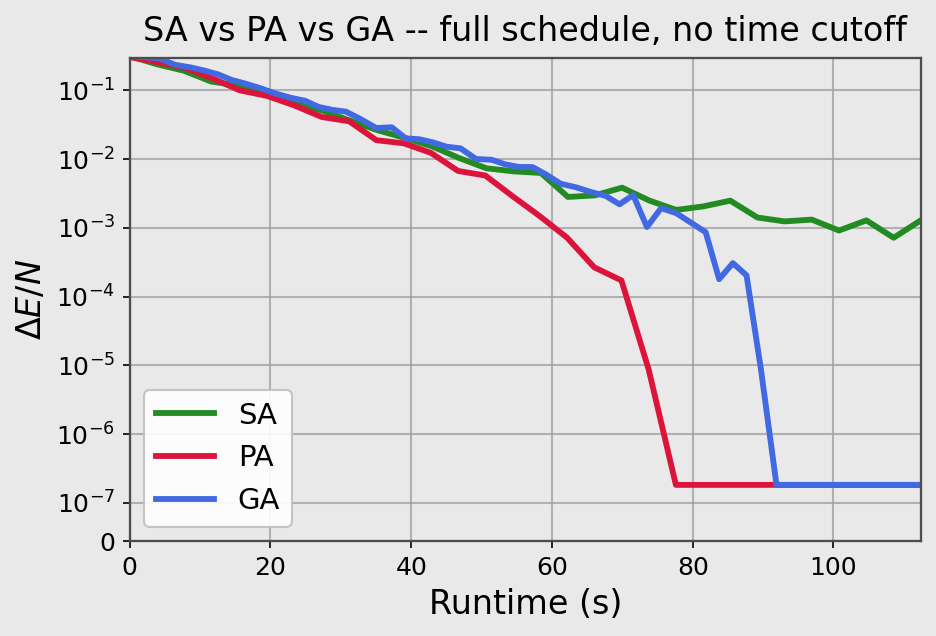

In [ ]:
plot_algos_comparison(results_SA=results_SA, results_PA=results_PA, results_GA=results_GA, normalize_by_N=True, N=N, output_path="fig1b_replica.png")


### Result discussion:

The figure shows the evolution of the best energy gap per spin, $\Delta E/N$, as a function of the runtime for Simulated Annealing (SA), Population Annealing (PA), and Global Annealing (GA). A smaller value of $\Delta E/N$ indicates that the algorithm has found a configuration closer to the reference ground state energy.

At short times, SA and PA reduce the energy faster than GA. This is expected because GA initially pays the additional computational cost of training and evaluating the MADE generative model. In contrast, SA and PA can immediately perform relatively inexpensive local Monte Carlo updates and in the case of PA population resampling.

As the simulation proceeds, the three algorithms show clearly different behaviors. SA rapidly improves at the beginning but eventually reaches a plateau around $\Delta E/N\sim 10^{-3}$. This suggests that the local checkerboard Metropolis dynamics becomes trapped in a region of the energy landscape and is unable to efficiently cross the barriers separating it from lower energy states.

PA continues to improve after SA has slowed down and reaches the reference ground state energy first, at approximately $80 s$. The resampling step allows low energy configurations to be preferentially replicated across the population, effectively propagating information about promising regions of configuration space.

GA decreases the energy more slowly during the first part of the annealing procedure. However, after approximately $80 s$, its energy gap drops rapidly by several orders of magnitude and the ground state energy is reached at around $100 s$. This behavior is consistent with the role of the MADE model: once the neural network has learned a sufficiently accurate approximation of the population distribution, it can propose global configurations that move between distant regions of configuration space. These global moves can overcome barriers that are difficult to cross using only local spin flips.

For this specific disorder instance, PA reaches the ground state faster than GA, while both algorithms clearly outperform SA at long times. However, a single trajectory is not sufficient to establish the general superiority of one algorithm. The comparison must be repeated over several independent disorder realizations, since the relative performance of PA and GA can depend strongly on the hardness of the specific spin-glass instance.

## Further analysis: $\Delta E(t)$ trace comparison (best_so_far vs. limited vs. raw)

The single panel plot above (Task 1) shows $\Delta E$ using whichever best_so_far /limit_jump convention was set in the parameter cell. Here we compare the three possible ways of recording $\Delta E(t)$ side by side across time_limits = [15, 50, 150] seconds:

1. **best_so_far**: the best (lowest) energy ever seen up to time t. Monotonically decreasing; shows how close the algorithm has gotten to the ground state.
2. **limited**: the instantaneous population energy, with large jumps limitation to avoid outlier spikes in the plot.
3. **raw**: the instantaneous population energy with no limiter. It shows the actual statistical fluctuations of the population.

All three runs reuse the same seeds (reset_trace_rng), so only the way $\Delta E$ is recorded changes across panels, not the underlying stochastic trajectory.



################################################################################
TRACE = best_so_far | TIME LIMIT = 15.0 s
################################################################################
SA temp_steps: 5
PA temp_steps: 5
GA temp_steps: 7

################################################################################
TRACE = best_so_far | TIME LIMIT = 50.0 s
################################################################################
SA temp_steps: 13
PA temp_steps: 13
GA temp_steps: 24

################################################################################
TRACE = best_so_far | TIME LIMIT = 150.0 s
################################################################################
SA temp_steps: 38
PA temp_steps: 38
GA temp_steps: 76
Plot saved to: fig1b_deltaE_best_so_far.png


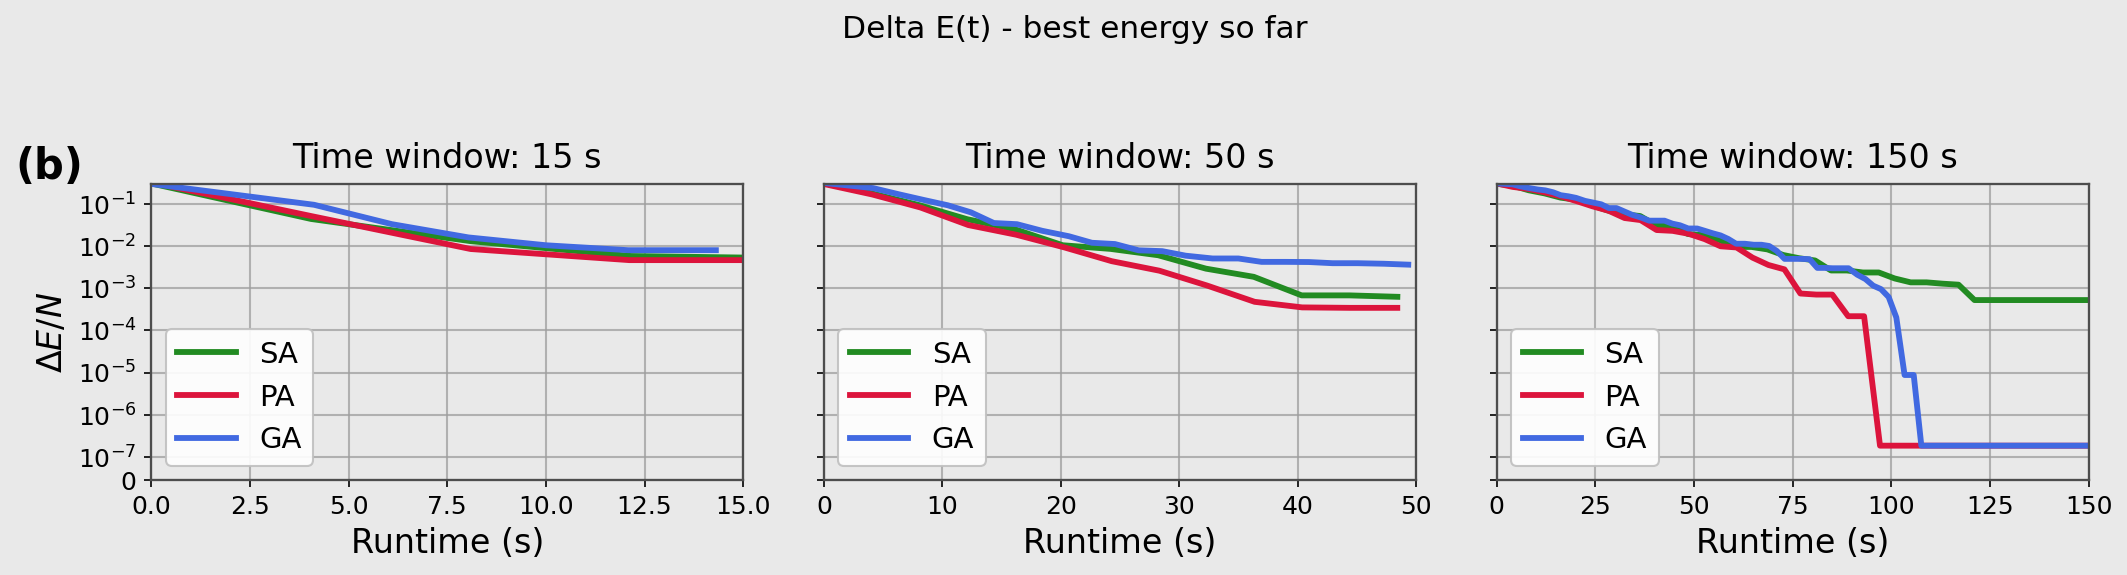


################################################################################
TRACE = limited | TIME LIMIT = 15.0 s
################################################################################
SA temp_steps: 5
PA temp_steps: 5
GA temp_steps: 7

################################################################################
TRACE = limited | TIME LIMIT = 50.0 s
################################################################################
SA temp_steps: 13
PA temp_steps: 13
GA temp_steps: 24

################################################################################
TRACE = limited | TIME LIMIT = 150.0 s
################################################################################
SA temp_steps: 38
PA temp_steps: 38
GA temp_steps: 76
Plot saved to: fig1b_deltaE_limited.png


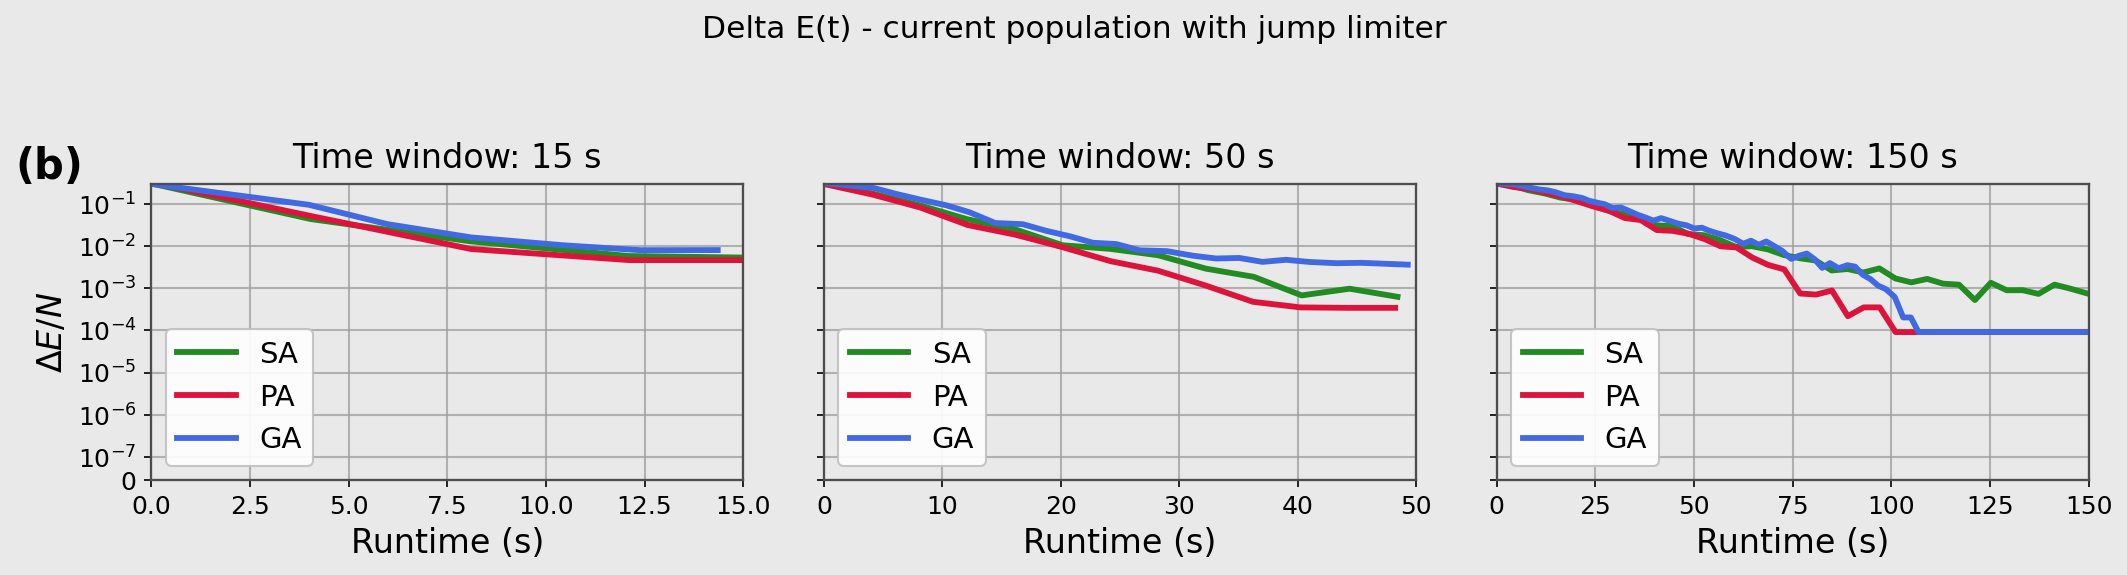


################################################################################
TRACE = raw | TIME LIMIT = 15.0 s
################################################################################
SA temp_steps: 5
PA temp_steps: 5
GA temp_steps: 7

################################################################################
TRACE = raw | TIME LIMIT = 50.0 s
################################################################################
SA temp_steps: 13
PA temp_steps: 13
GA temp_steps: 24

################################################################################
TRACE = raw | TIME LIMIT = 150.0 s
################################################################################
SA temp_steps: 38
PA temp_steps: 38
GA temp_steps: 76
Plot saved to: fig1b_deltaE_raw.png


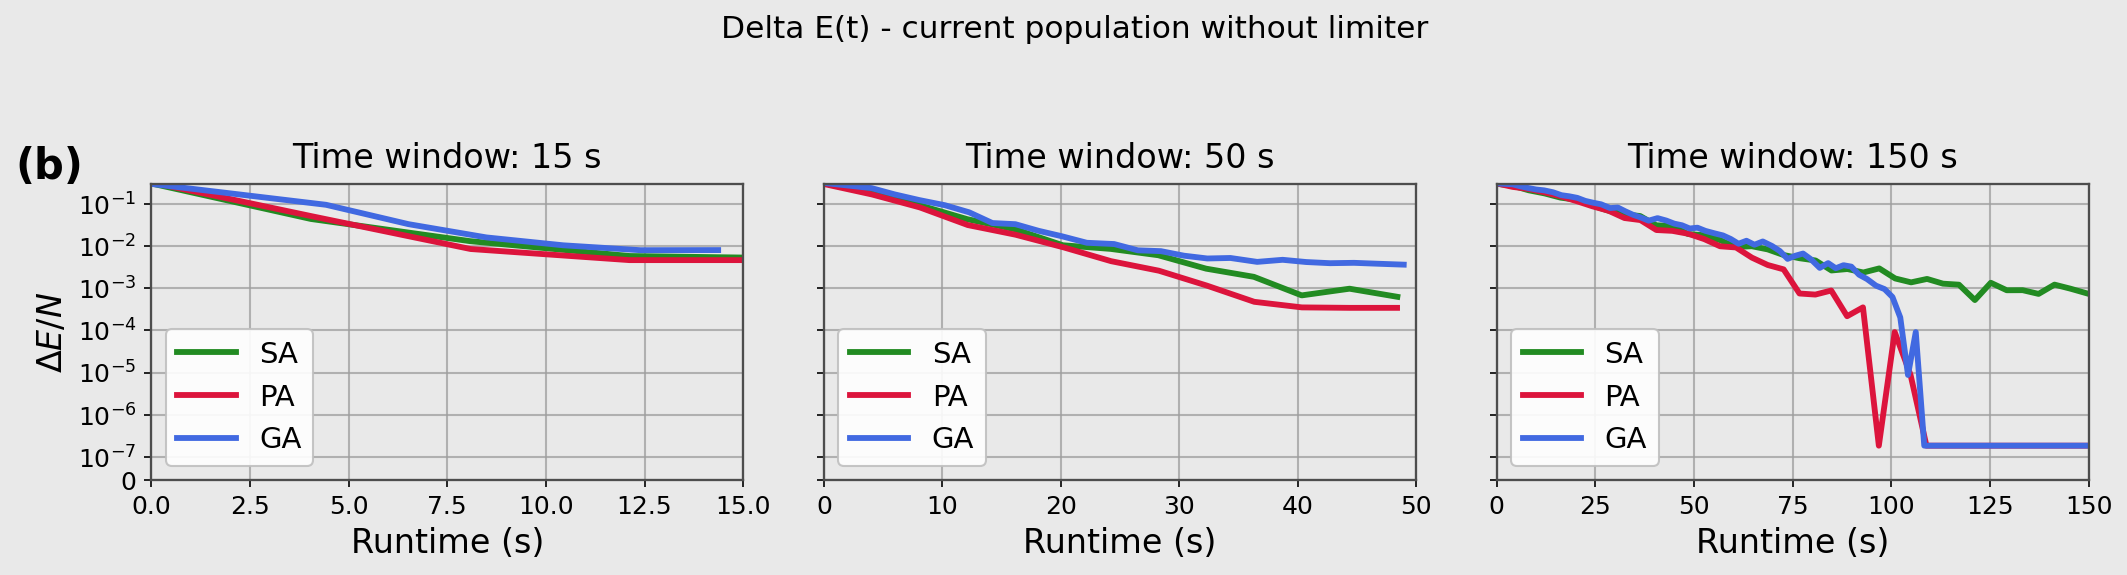

In [37]:
time_limits = [15.0, 50.0, 150.0]

# Righe: SA, PA, GA
# Colonne: time_limits = [15.0, 50.0, 150.0]
temp_steps_trace = np.array([
    [5,    13,    38],      # SA
    [5,    13,    38],      # PA
    [7, 24, 76],   # GA
], dtype=int)


def reset_trace_rng(seed_value):
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed_value)
    np.random.seed(seed_value % (2**32 - 1))
    random.seed(seed_value)


def get_trace_temp_steps(temp_steps_matrix, algorithm_idx, time_idx):
    temp_steps_matrix = np.asarray(temp_steps_matrix)

    expected_shape = (3, len(time_limits))
    if temp_steps_matrix.shape != expected_shape:
        raise ValueError(f"temp_steps_trace must have shape {expected_shape}: rows = SA/PA/GA, columns = time_limits.")

    return int(temp_steps_matrix[algorithm_idx, time_idx])


def run_deltaE_three_panel_trace(trace_label, limit_jump_trace, best_so_far_trace, temp_steps_matrix=temp_steps_trace):
    results_SA_trace = []
    results_PA_trace = []
    results_GA_trace = []

    for time_idx, time_limit in enumerate(time_limits):
        print("\n" + "#" * 80)
        print(f"TRACE = {trace_label} | TIME LIMIT = {time_limit} s")
        print("#" * 80)

        seed_base_trace = seed + int(round(1000 * time_limit))

        temp_steps_SA_trace = get_trace_temp_steps(temp_steps_matrix, algorithm_idx=0, time_idx=time_idx)
        temp_steps_PA_trace = get_trace_temp_steps(temp_steps_matrix, algorithm_idx=1, time_idx=time_idx)
        temp_steps_GA_trace = get_trace_temp_steps(temp_steps_matrix, algorithm_idx=2, time_idx=time_idx)

        print(f"SA temp_steps: {temp_steps_SA_trace}")
        print(f"PA temp_steps: {temp_steps_PA_trace}")
        print(f"GA temp_steps: {temp_steps_GA_trace}")

        reset_trace_rng(seed_base_trace + 101)
        temperatures_SA, observ_SA, population_SA, samples_SA = simulated_annealing(L=L, J=J, T_min=T_min, T_max=T_max, temp_steps=temp_steps_SA_trace, pop_size=pop_size, high_thermalisation_steps=high_thermalisation_steps, mc_steps=mc_steps, mode="optimizer", gurobi_energy=gurobi_energy, limit_jump=limit_jump_trace, best_so_far=best_so_far_trace, time_limit=time_limit, n_samples=0, save_configs=False)

        trace_data_SA = build_trace_data(observ_SA, ground_state_tol=GROUND_STATE_TOL)
        results_SA_trace.append({"time_limit": time_limit, "temperatures": temperatures_SA, "observ": observ_SA, "population": population_SA, "samples": samples_SA, "trace_data": trace_data_SA})

        reset_trace_rng(seed_base_trace + 202)
        temperatures_PA, observ_PA, population_PA, samples_PA = population_annealing(L=L, J=J, T_min=T_min, T_max=T_max, temp_steps=temp_steps_PA_trace, pop_size=pop_size, high_thermalisation_steps=high_thermalisation_steps, mc_steps=mc_steps, mode="optimizer", gurobi_energy=gurobi_energy, limit_jump=limit_jump_trace, best_so_far=best_so_far_trace, time_limit=time_limit, n_samples=0, save_configs=False)

        trace_data_PA = build_trace_data(observ_PA, ground_state_tol=GROUND_STATE_TOL)
        results_PA_trace.append({"time_limit": time_limit, "temperatures": temperatures_PA, "observ": observ_PA, "population": population_PA, "samples": samples_PA, "trace_data": trace_data_PA})

        reset_trace_rng(seed_base_trace + 303)
        temperatures_GA, observ_GA, population_GA, samples_GA, model_GA = global_annealing(L=L, J=J, pop_size=pop_size, MLMC_steps=MLMC_steps, swap_step=swap_step, T_min=T_min, T_max=T_max, temp_steps=temp_steps_GA_trace, mode="optimizer", gurobi_energy=gurobi_energy, limit_jump=limit_jump_trace, best_so_far=best_so_far_trace, high_thermalisation_steps=high_thermalisation_steps, batch_size=batch_size, num_epochs_start=num_epochs_start, num_epochs_retrain=num_epochs_retrain, time_limit=time_limit, n_samples=0, save_configs=False)

        trace_data_GA = build_trace_data(observ_GA, ground_state_tol=GROUND_STATE_TOL)
        results_GA_trace.append({"time_limit": time_limit, "temperatures": temperatures_GA, "observ": observ_GA, "population": population_GA, "samples": samples_GA, "model": model_GA, "trace_data": trace_data_GA})

    return results_SA_trace, results_PA_trace, results_GA_trace


deltaE_trace_configs = [
    {"name": "best_so_far", "title": "Delta E(t) - best energy so far", "limit_jump": False, "best_so_far": True, "output_path": "fig1b_deltaE_best_so_far.png"},
    {"name": "limited", "title": "Delta E(t) - current population with jump limiter", "limit_jump": True, "best_so_far": False, "output_path": "fig1b_deltaE_limited.png"},
    {"name": "raw", "title": "Delta E(t) - current population without limiter", "limit_jump": False, "best_so_far": False, "output_path": "fig1b_deltaE_raw.png"},
]

deltaE_trace_results = {}

for cfg in deltaE_trace_configs:
    results_SA_cfg, results_PA_cfg, results_GA_cfg = run_deltaE_three_panel_trace(trace_label=cfg["name"], limit_jump_trace=cfg["limit_jump"], best_so_far_trace=cfg["best_so_far"], temp_steps_matrix=temp_steps_trace)

    deltaE_trace_results[cfg["name"]] = {"SA": results_SA_cfg, "PA": results_PA_cfg, "GA": results_GA_cfg}

    plot_three_algos_three_panels_paper_style(results_SA=results_SA_cfg, results_PA=results_PA_cfg, results_GA=results_GA_cfg, time_limits=time_limits, output_path=cfg["output_path"], normalize_by_N=True, N=N, ymin=0.0, ymax=3e-1, ground_state_tol=GROUND_STATE_TOL, figure_title=cfg["title"])

### Results discussion:

The three plots show the evolution of the energy gap per spin, $\Delta E/N$, for SA, PA, and GA over three runtime windows. The $15 s$ and $50 s$ panels mainly describe the early and intermediate stages of the annealing, while the $150 s$ panel highlights the long-time behavior of the algorithms.

In the first plot, the best-so-far energy is shown. By construction these curves can only decrease: once an algorithm finds a lower energy configuration, that value is retained. This makes the plot particularly useful for optimization, since it directly measures the best solution found up to a given time. SA improves rapidly at the beginning but eventually reaches a plateau, while PA and GA continue exploring lower energy regions and finally reach the reference ground state energy, as we have noted in the previous plot.

The second plot shows the energy of the current population with the jump limiter enabled. The limiter suppresses large upward jumps in the recorded energy, so the curves remain relatively smooth and mainly emphasize the overall downward trend of the annealing process. In this representation, PA and GA again reach much lower energies than SA, but temporary losses of good configurations are partially hidden by the no jump condition.

The third plot removes the limiter and therefore shows the true instantaneous behavior of the current population. Here, interesting upward jumps become visible. In particular, PA temporarily reaches a very low-energy configuration around $95 s$, but the following population evolves toward a worse state and the energy gap increases again. Physically, this means that the algorithm has discovered a very good region of configuration space but has not preserved it in the subsequent population.

GA shows a different behavior. Although some fluctuations are present near the minimum, it does not exhibit the same large unfavorable jump observed for PA. Once GA reaches the low energy region, the population remains much closer to it and rapidly reaches the reference ground state. This suggests that the global proposals generated by MADE may help the population remain connected to favorable regions of configuration space instead of completely losing the information associated with a good configuration.

The comparison between the plots with and without the limiter is therefore useful: the limiter provides a cleaner view of the general optimization trend, while the unrestricted trace reveals the actual population dynamics and shows whether a low-energy state is stable or only visited temporarily.


# Task 2: Sampler

This section switches from optimization to fixed-temperature sampling. SA, PA, and GA first cool to T_sample, then they continue at fixed temperature so their final populations can be compared through energy histograms and overlap distributions.


In [40]:
L = 10
N = L**3

SAMPLER_CONFIG = {"seed": 310411727, "T_sample": 0.77, "temp_steps": 100, "n_samples": 100, "thin_steps": 20, "save_configs": False, "ga_mode": "local", "ga_local_steps": None, "ga_global_steps": 5, "ga_retrain_every": 50, "ga_retrain_epochs": 1}

if SAMPLER_CONFIG["ga_local_steps"] is None:
    SAMPLER_CONFIG["ga_local_steps"] = SAMPLER_CONFIG["thin_steps"]

#short GA reference runs for sampler stage
PQ_REFERENCE_SEED = SAMPLER_CONFIG["seed"]
T_sample = SAMPLER_CONFIG["T_sample"]
temp_steps_sampler = SAMPLER_CONFIG["temp_steps"]
n_samples = SAMPLER_CONFIG["n_samples"]
save_configs = SAMPLER_CONFIG["save_configs"]

seed_sampler = validate_seed_has_overlap_reference(PQ_REFERENCE_SEED, T_target=T_sample, pq_dir=PQ_DIR)
coupling_path_s = coupling_file(seed_sampler)
J_sampler = read_couplings(coupling_path_s, N).to(device)


## Energy distribution
we observe the collected energy distribution and evaluate the three algorithms.

In [41]:
print("Running SA sampler...")
_, observ_SA_s, pop_SA_s, _ = simulated_annealing(L=L, J=J_sampler, T_min=T_sample, T_max=T_max, temp_steps=temp_steps_sampler, pop_size=pop_size, high_thermalisation_steps=high_thermalisation_steps, mc_steps=mc_steps, mode="sampler", n_samples=n_samples, save_configs=save_configs, thin_steps=SAMPLER_CONFIG["thin_steps"])
print("  done.")

print("Running PA sampler...")
_, observ_PA_s, pop_PA_s, _ = population_annealing(L=L, J=J_sampler, T_min=T_sample, T_max=T_max, temp_steps=temp_steps_sampler, pop_size=pop_size, high_thermalisation_steps=high_thermalisation_steps, mc_steps=mc_steps, mode="sampler", n_samples=n_samples, save_configs=save_configs, thin_steps=SAMPLER_CONFIG["thin_steps"])
print("  done.")

print("Running GA sampler...")
_, observ_GA_s, pop_GA_s, _, model_GA_s = global_annealing(L=L, J=J_sampler, pop_size=pop_size, MLMC_steps=MLMC_steps, swap_step=swap_step, T_min=T_sample, T_max=T_max, temp_steps=temp_steps_sampler, mode="sampler", high_thermalisation_steps=high_thermalisation_steps, batch_size=batch_size, num_epochs_start=num_epochs_start, num_epochs_retrain=num_epochs_retrain, n_samples=n_samples, save_configs=save_configs, sampler_mode=SAMPLER_CONFIG["ga_mode"], sampler_local_steps=SAMPLER_CONFIG["ga_local_steps"], sampler_global_steps=SAMPLER_CONFIG["ga_global_steps"], sampler_retrain_every=SAMPLER_CONFIG["ga_retrain_every"], sampler_retrain_epochs=SAMPLER_CONFIG["ga_retrain_epochs"])
print("Done")

# Bundle results for plotting
sampler_results = {"SA": {"observ": observ_SA_s, "population": pop_SA_s}, "PA": {"observ": observ_PA_s, "population": pop_PA_s}, "GA": {"observ": observ_GA_s, "population": pop_GA_s}}


Running SA sampler...
  done.
Running PA sampler...
  done.
Running GA sampler...
Done


Plot saved to: sampler_energy_hist.png


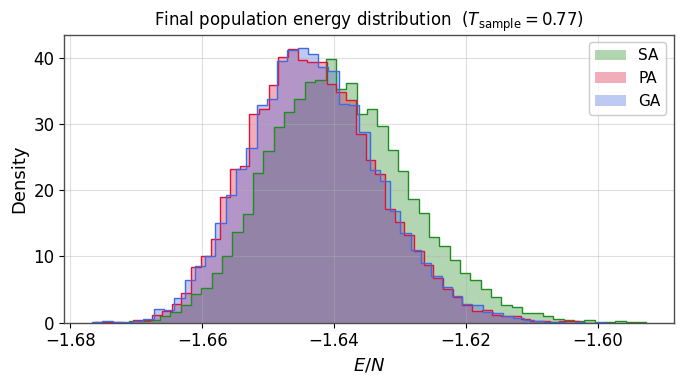

In [42]:
# Plot 1: energy histogram of the final population
plot_energy_histogram(sampler_results, J_sampler, N, T_sample)

### Results discussion:
This plot compares the final energy-per-spin distributions obtained by SA, PA, and GA at $T_{sample}=0.77$. Unlike the previous optimization plots, which focus only on the lowest energy found, this histogram describes the whole final population produced by each algorithm.

PA and GA show very similar distributions, both centered at lower energies than SA. Their strong overlap indicates that the two algorithms explore comparable low-energy regions of configuration space at this temperature.

The SA distribution is instead visibly shifted toward higher energies and is slightly broader on the high-energy side. This suggests that local Metropolis updates alone have more difficulty efficiently equilibrating the population and reaching the lower-energy configurations sampled by PA and GA.

The difference is particularly important from a sampling point of view. A good optimizer only needs to find one very low energy configuration, while a good sampler should generate an entire population representative of the relevant probability distribution. Here, PA and GA do not simply find isolated low energy states: a large fraction of their final populations is concentrated at lower energies.

GA is especially interesting because its distribution is very close to that of PA despite using MADE generated global proposals. The generative model therefore appears able to propose configurations in physically relevant low energy regions, while the Metropolis-Hastings correction and local Monte Carlo moves maintain the sampling dynamics.

Overall, the plot suggests that at T=0.77, PA and GA provide more efficient access to low-energy configurations than SA, while GA reproduces an energy distribution remarkably similar to PA.

## GA Sampler Modes and Overlap at T = 0.77

The fixed-temperature sampler phase is handled by the shared run_fixed_temperature_sampler function through global_annealing(mode="sampler"). Every GA regime below is obtained by calling GA with different sampler parameters while reusing the same thermalized starting population and MADE model (pop_GA_s, model_GA_s from the Task-2 sampler run).

The GA regimes are:

1. **local** -- checkerboard Metropolis moves only (sampler_mode="local").
2. **local + global (frozen)** -- local moves plus MADE/MLMC global moves, with the model kept fixed (sampler_mode="local_global").
3. **local + global + retrain/k** -- same global sampler, but the MADE model is retrained every k updates (sampler_mode="local_global_retrain").

The overlap comparison is performed at $T_{sample} = 0.77$. The final $P(q)$ plot includes SA, PA, all GA sampler regimes, and the exact/reference Pq_PA_310411727_reference.npy curve as a grey background in every panel.

In [43]:
def get_reference_ground_state(seed, N, ga_dirs=None):
    """
    Resolve a per-spin ground-state reference energy for `seed`.

    Priority:
      1. Gurobi log file `log_{seed}.txt` (total energy -> divided by N).
      2. Long/reference GA result files, whose `minEnergy` column is already per spin. This includes the Alpha long-GA references and the Omega success-rate references used by the P(q) sampler seed.
    """
    log_path = gurobi_log_file(seed)
    checked = [str(log_path)]
    if os.path.exists(log_path):
        return read_gurobi_energy(log_path) / N

    if ga_dirs is None:
        ga_dirs = []
    elif isinstance(ga_dirs, (str, os.PathLike)):
        ga_dirs = [ga_dirs]

    for ga_dir in ga_dirs:
        candidate = os.path.join(ga_dir, f"results_{seed}.txt")
        checked.append(candidate)
        if os.path.exists(candidate):
            df = pd.read_csv(candidate, sep=r"\s+", header=None, names=["gsteps", "lsteps", "nTemps", "schedule", "minEnergy", "AvgEnergy", "Runtime"])
            return float(df["minEnergy"].min())

    print(f"[WARN] No ground-state reference found for seed {seed} "
          f"(looked for {checked}).")
    return None

def _retrain_variant_name(k):
    """Canonical variant key for 'retrain the MADE model every k updates'."""
    return f"local_global_retrain_{k}"


def make_ga_sampler_variant_configs(local_steps=1, global_steps=1, retrain_intervals=(50, 10)):
    """Build the GA sampler parameter sets used in the mode comparison."""
    configs = [
        {"name": "local", "sampler_mode": "local","sampler_local_steps": local_steps, "sampler_global_steps": 0, "sampler_retrain_every": None},
        {"name": "local_global", "sampler_mode": "local_global", "sampler_local_steps": local_steps, "sampler_global_steps": global_steps, "sampler_retrain_every": None},
    ]
    for k in retrain_intervals:
        configs.append({"name": _retrain_variant_name(k), "sampler_mode": "local_global_retrain", "sampler_local_steps": local_steps,"sampler_global_steps": global_steps, "sampler_retrain_every": int(k)})
    return configs


def run_ga_sampler_variants(J, L, population_init, model_init, T_sample, n_updates=2000, variant_configs=None, num_epochs_start=40, retrain_epochs=1, batch_size=256, gs_energy_per_spin=None):
    """
    Run several fixed-T GA sampler modes through global_annealing(mode="sampler").

    Each variant starts from the same population/model and skips the annealing
    warmup, so only the fixed-temperature sampler parameters differ.
    """
    if variant_configs is None:
        variant_configs = make_ga_sampler_variant_configs()

    results = {}
    for cfg in variant_configs:
        _, observ, final_population, _, final_model = global_annealing(L=L, J=J, pop_size=population_init.shape[0], MLMC_steps=0, swap_step=0, T_min=T_sample, T_max=T_sample, temp_steps=1, mode="sampler", high_thermalisation_steps=0, batch_size=batch_size, num_epochs_start=num_epochs_start, num_epochs_retrain=retrain_epochs, n_samples=n_updates, save_configs=False, sampler_mode=cfg["sampler_mode"], sampler_local_steps=cfg["sampler_local_steps"], sampler_global_steps=cfg["sampler_global_steps"], sampler_retrain_every=cfg["sampler_retrain_every"], sampler_retrain_epochs=retrain_epochs, sampler_record_diagnostics=True, sampler_gs_energy_per_spin=gs_energy_per_spin, initial_population=population_init, initial_model=model_init, skip_annealing=True)
        trace = dict(observ.sampler_trace)
        trace["final_population"] = final_population
        trace["final_model"] = final_model
        trace["sampler_config"] = dict(cfg)
        results[cfg["name"]] = trace

    return results


### sampler mode comparison

This cell compares local-only GA sampling, local+global sampling with a frozen MADE model, and local+global sampling with periodic retraining. All variants start from the same population/model so the sampler settings are the only intended difference.


In [46]:
# GA sampler mode comparison. Every variant starts from the same pop_GA_s / model_GA_s produced in the Task-2 sampler warmup above.
GA_DIR = "/content/MLMC_optimization/Data/GA"
OMEGA_SUCCESS_GA_DIR = "/content/MLMC_optimization/Data/Omega/Success/GA"
N_SAMPLER_UPDATES = 2000
RETRAIN_INTERVALS = [50, 10]
RETRAIN_EPOCHS = 1
seed=310411727

GA_MODE_LOCAL_STEPS = 1
GA_MODE_GLOBAL_STEPS = 1

GA_SAMPLER_VARIANTS = make_ga_sampler_variant_configs(local_steps=GA_MODE_LOCAL_STEPS, global_steps=GA_MODE_GLOBAL_STEPS, retrain_intervals=RETRAIN_INTERVALS)

gs_energy_sampler = get_reference_ground_state(seed_sampler, N, ga_dirs=[GA_DIR, OMEGA_SUCCESS_GA_DIR])
if gs_energy_sampler is not None:
    print(f"Reference ground-state energy per spin (seed {seed_sampler}): {gs_energy_sampler:.5f}")

ga_sampler_results = run_ga_sampler_variants(J=J_sampler, L=L, population_init=pop_GA_s, model_init=model_GA_s, T_sample=T_sample, n_updates=N_SAMPLER_UPDATES, variant_configs=GA_SAMPLER_VARIANTS, retrain_epochs=RETRAIN_EPOCHS, batch_size=batch_size, gs_energy_per_spin=gs_energy_sampler)

for variant in _ordered_variants(ga_sampler_results.keys()):
    data = ga_sampler_results[variant]
    acc = data["acc_rate"]
    mean_acc = None if len(acc) == 0 or np.all(np.isnan(acc)) else np.nanmean(acc)
    best_final = data["delta_E_best"][-1] if "delta_E_best" in data and len(data["delta_E_best"]) else None
    best_text = "n/a" if best_final is None else f"{best_final:.3e}"
    acc_text = "n/a" if mean_acc is None else f"{mean_acc:.3f}"
    print(f"{variant:>26s}: final best-so-far Delta E/N = {best_text}, mean MADE acceptance rate = {acc_text}")

[WARN] No ground-state reference found for seed 310411727 (looked for ['/content/MLMC_optimization/Data/Alpha/gurobi_logs/log_310411727.txt', '/content/MLMC_optimization/Data/GA/results_310411727.txt', '/content/MLMC_optimization/Data/Omega/Success/GA/results_310411727.txt']).
                     local: final best-so-far Delta E/N = n/a, mean MADE acceptance rate = n/a
              local_global: final best-so-far Delta E/N = n/a, mean MADE acceptance rate = 0.057
   local_global_retrain_10: final best-so-far Delta E/N = n/a, mean MADE acceptance rate = 0.097
   local_global_retrain_50: final best-so-far Delta E/N = n/a, mean MADE acceptance rate = 0.069


### Overlap probability distribution $P(q)$ at $T=0.77$
**Overlap definition:** Given two spin configurations  $\mathbf{s}^a, \mathbf{s}^b \in \{-1,+1\}^N$ (two independent replicas evolving under the same disorder $J$), the overlap is defined as

$$
q_{ab} = \frac{1}{N}\sum_{i=1}^{N} s_i^a\, s_i^b \in [-1, 1].
$$

It measures how similar the two configurations are: $q=1$ means that the configurations are identical, $q=-1$ means that one is the global spin-flip image of the other, and $q \approx 0$ means that the configurations are essentially uncorrelated.

Here the comparison uses $T_{sample} = 0.77$ and includes SA, PA, and all GA variants. In each panel, the exact/reference distribution loaded from Data/Omega/Pq/Pq_PA_310411727_reference.npy at the same temperature is shown in the background. This makes it easy to see whether the sampled distribution has the same width and structure as the reference.

The overlap distribution P(q) tells us how similar two independent spin configurations are. At high temperature, the system moves easily through configuration space and different replicas are almost unrelated. Their overlap is therefore usually close to zero, so $P(q)$ has a single peak around q=0.
At low temperature, the system tends to remain in low energy regions and different replicas can end up in similar configurations. They may also reach the globally spin flipped version of the same configuration (which is energetically equivalent due to the Hamiltonian properties). As a result, large positive and negative values of $q$ become more likely, and $P(q)$ develops peaks away from zero.

Plot saved to: overlap_Pq_T077_SA_PA_GA_reference.png


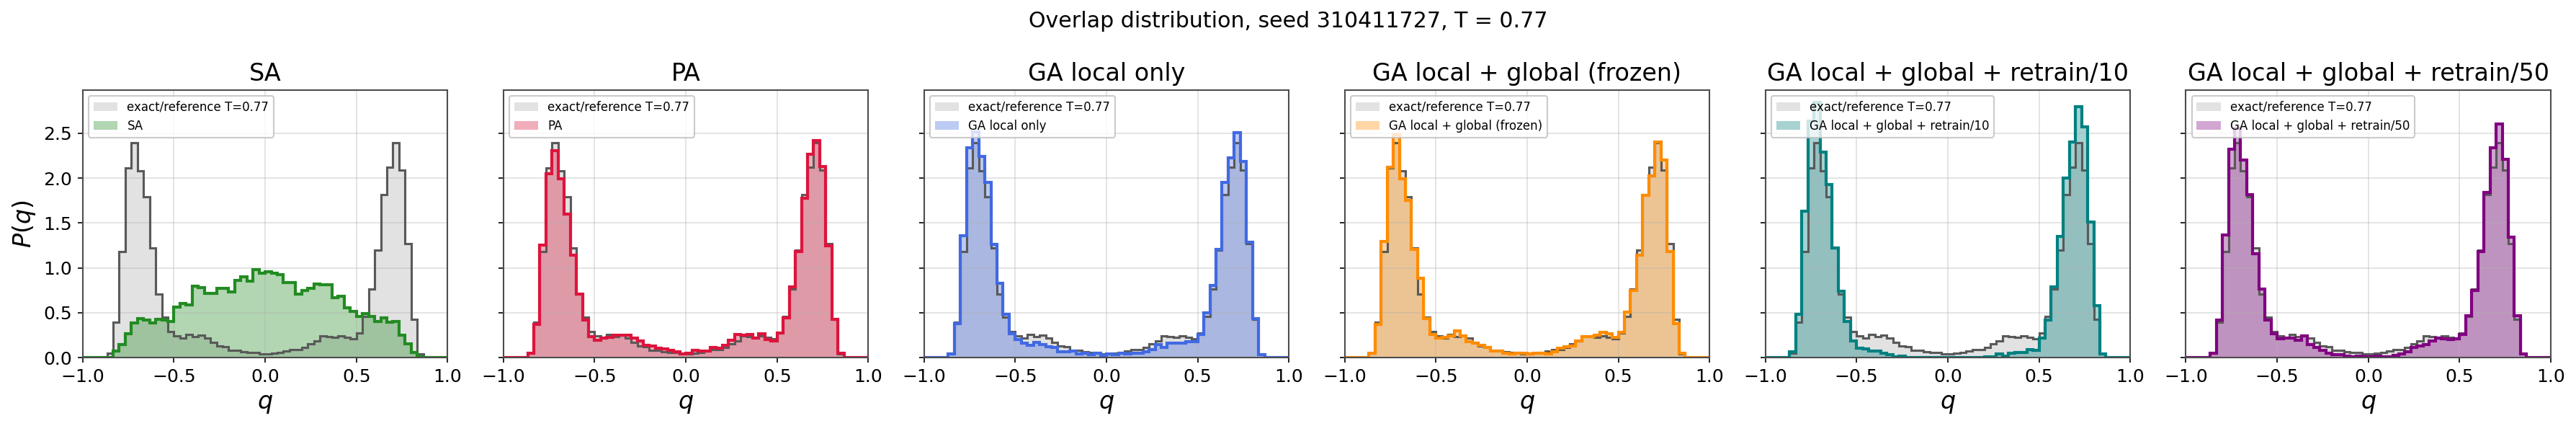

In [47]:
def compute_pairwise_overlap_histogram(population, max_pairs=20000):
    """
    Full (or randomly subsampled) set of pairwise overlaps q_ab = (1/N) s_a . s_b
    across all replicas of a single population.
    """
    n, N = population.shape
    iu = torch.triu_indices(n, n, offset=1, device=population.device)
    if iu.shape[1] > max_pairs:
        perm = torch.randperm(iu.shape[1], device=population.device)[:max_pairs]
        iu = iu[:, perm]
    Q = (population[iu[0]].double() * population[iu[1]].double()).sum(dim=1) / N
    return Q.detach().cpu().numpy()


def load_exact_overlap_reference(T_target=0.77, seed=310411727, pq_dir=PQ_DIR):
    """Load the exact/reference P(q) samples closest to T_target."""
    pq_path, temp_path = pq_reference_files(seed, pq_dir=pq_dir)
    if not pq_path.exists() or not temp_path.exists():
        print(f"[WARN] Exact P(q) reference not found: {pq_path} / {temp_path}")
        return None

    temperatures = np.load(temp_path)
    idx = int(np.argmin(np.abs(temperatures - T_target)))
    q_ref = np.asarray(np.load(pq_path, mmap_mode="r")[idx], dtype=float)
    return {"q": q_ref, "T": float(temperatures[idx]), "path": pq_path}




pq_data = {"SA": compute_pairwise_overlap_histogram(pop_SA_s), "PA": compute_pairwise_overlap_histogram(pop_PA_s)}
for variant in _ordered_variants(ga_sampler_results.keys()):
    final_pop = ga_sampler_results[variant]["final_population"]
    pq_data[variant] = compute_pairwise_overlap_histogram(final_pop)

exact_pq_reference = load_exact_overlap_reference(T_target=T_sample, seed=PQ_REFERENCE_SEED)
plot_pq_histograms(pq_data, T_sample=T_sample, seed=seed_sampler, exact_reference=exact_pq_reference)

### Results discussion:
The figure compares the overlap distribution $P(q)$ obtained with the different algorithms at $T=0.77$. The gray curve represents the reference equilibrium distribution.

The reference distribution has two symmetric peaks at large positive and negative overlap. This means that, at this temperature, independent replicas often fall into similar low energy configurations or into configurations related by the global spin-flip symmetry.

SA fails to reproduce this structure. Its distribution is broad and mostly concentrated around $q=0$, showing that the replicas remain weakly correlated and do not correctly explore the low temperature structure of the configuration space.

PA reproduces the reference distribution much more accurately. The two peaks appear at the correct overlap values and the symmetry between positive and negative q is preserved. This indicates a much better description of the relevant low energy states.

The GA local only case already performs significantly better than SA as even though the sampling does not involve global steps, the initial configuration from which it starts has been annealed with a regular GA. However some differences with the reference distribution remain, especially in the weight between the two peaks.

Adding MADE generated global moves improves the agreement with the reference distribution. The local + global sampler with a frozen model reproduces both peaks and the overall shape of $P(q)$ much more closely. This suggests that global proposals help the population move between distant low energy regions that are difficult to connect using only local spin flips.

Periodically retraining MADE does not produce a major qualitative change in this example, since both retraining every 10 and every 50 sampling steps preserve the bimodal structure of $P(q)$ and remain relatively close to the reference distribution. However, more frequent retraining does not necessarily improve the sampler. Retraining every 10 steps may cause MADE to adapt too quickly to temporary biases in the current population, reinforcing already overrepresented low energy regions and reducing the exploration of intermediate overlap states. A longer retraining interval gives the population more time to explore configuration space before updating the proposal model. Overall, the difference between the two retraining frequencies is smaller than the much larger improvement obtained by introducing global MADE moves.

## Acceptance rate vs. retraining

Plots the MADE acceptance rate for the same Task-2 disorder realization used above (seed_sampler). The curves are single instance traces for the frozen local+global sampler and the retrained variants.


Plot saved to: ga_acceptance_vs_retrain.png


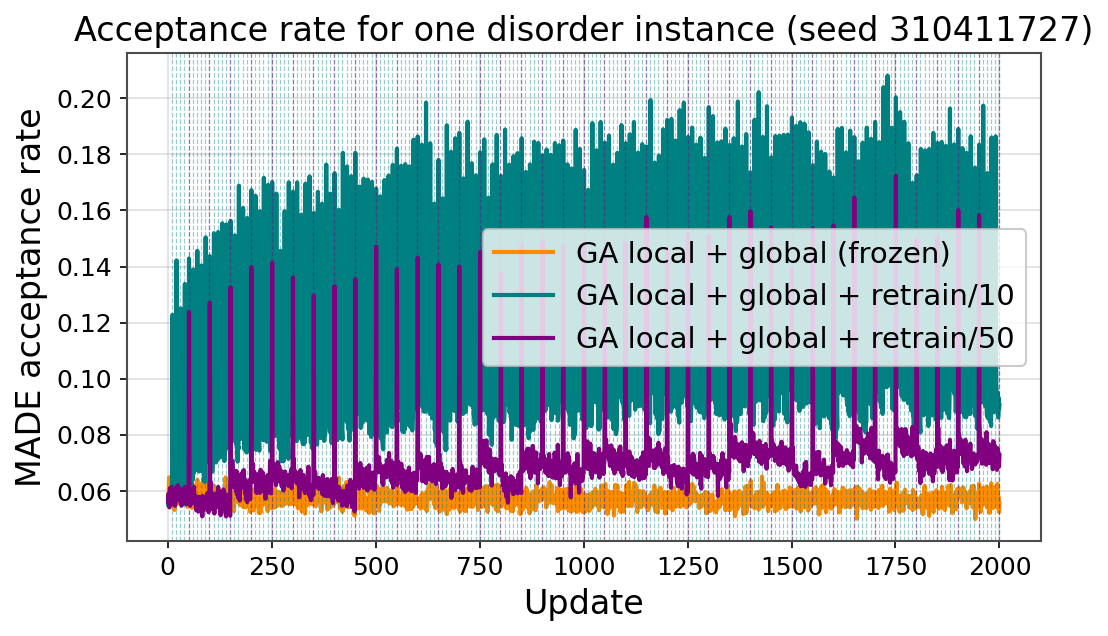

In [48]:
plot_acceptance_rate_retrain_effect(ga_sampler_results, retrain_intervals=RETRAIN_INTERVALS, seed=seed_sampler)

### Results discussion
The figure shows the MADE acceptance rate during fixed-temperature GA sampling for three different strategies: a frozen model, retraining every 10 updates, and retraining every 50 updates.

With a frozen MADE model, the acceptance rate remains almost constant around 5%. This indicates that, as the population evolves, the proposal distribution learned before the sampling phase is no longer perfectly adapted to the current configurations. The Metropolis-Hastings correction therefore rejects most of the global proposals.

Retraining MADE improves the acceptance rate because the proposal model is updated using the current population. The effect is particularly strong for retraining every 10 updates, where the acceptance rate becomes much larger and can reach values close to 20%. This means that the generated configurations are more compatible with the current target distribution and are accepted more frequently.

However, a higher acceptance rate does not automatically imply better sampling. As observed in the overlap distribution, retraining every 10 steps gives a less accurate $P(q)$ than some of the other GA variants. A possible explanation is that the network adapts too quickly to temporary biases in the current population. MADE then proposes configurations similar to already overrepresented states: these proposals are accepted more easily, but the exploration of other regions of configuration space can be reduced.

Retraining every 50 updates gives a more moderate increase in acceptance rate. The periodic peaks visible after retraining indicate that updating the model temporarily improves the quality of the global proposals. Between retraining events, the acceptance rate gradually returns toward a lower baseline as the population evolves away from the distribution learned by MADE.

Overall, the figure highlights an important trade off: frequent retraining increases the acceptance of global moves, but excessive adaptation can reduce population diversity and worsen the exploration of configuration space. Therefore, the acceptance rate alone is not sufficient to evaluate the quality of the sampler and must be considered together with observables such as the overlap distribution $P(q)$.

# Task 3: From EA to SK
The Sherrington–Kirkpatrick model is a mean-field spin-glass model in which every spin interacts with every other spin. Its Hamiltonian is
$$ \mathcal{H}=-\sum_{i<j} J_{ij} s_i s_j$$

where $s_i \in {-1, +1}$ and the couplings are usually drawn from a Gaussian distribution, $J_{ij}\sim \mathcal{N}(0, \frac{1}{N})$

Unlike the three dimensional Edwards–Anderson model, the SK model has no spatial lattice or nearest neighbor geometry. The interaction matrix is dense, so each spin is coupled to all the other N−1 spins. This makes the model fully connected and prevents the use of the checkerboard update employed for the cubic EA lattice.

The SK model is useful because it provides a different and non local spin glass energy landscape. Studying SA, PA and GA on this model allows us to test whether their behavior depends on the local geometry of the EA lattice or remains similar in fully connected disordered systems.

## Extension to the Sherrington-Kirkpatrick model
We now extend the comparison of SA, PA and GA from the three-dimensional Edwards-Anderson model to the Sherrington-Kirkpatrick model.
The annealing logic remains unchanged, but two model-specific components must be modified:
1. The coupling matrix is now dense, since every spin interacts with every other spin.
2. The checkerboard update cannot be used, because the SK model has no bipartite lattice structure. It is therefore replaced by sequential single-spin Metropolis updates.

To keep this section independent and easier to read, simplified SK-specific versions of Observables, trace-data construction, SA, PA and GA are defined below. These functions contain only the components required for the optimizer comparison and avoid modifying the original EA implementation.
The function belove generates random couplings distributed as described

In [49]:
def generate_sk_couplings(N, seed, device):
    """
    Generate the dense coupling matrix of the SK model.

    J_ij ~ N(0, 1/N), with J_ij = J_ji and J_ii = 0.
    """
    torch.manual_seed(seed)

    J = torch.randn(N, N, device=device) / np.sqrt(N)
    #Keep only the upper triangular part and symmetrize
    J = torch.triu(J, diagonal=1)
    J = J + J.T

    return J

### Updated montecarlo steps
In the SK model, every spin interacts with all the others. Therefore, the checkerboard update used for the EA lattice cannot be applied, because spins updated at the same time would directly interact.

The code instead performs a sequential single spin Metropolis sweep. For each spin, it computes $\Delta E_i=2s_ih_i$ and $h_i=\sum_j J_{ij}s_j$, and accepts the flip with probability $\min(1, e^{-\beta \Delta E_i})$.
After an accepted flip, all local fields are updated immediately.

In [50]:
def montecarlo_step_sk(population, J, T):
    """
    Perform one sequential single-spin Metropolis sweep for the SK model.

    Since every spin interacts with every other spin, checkerboard parallel
    updates cannot be used.
    """
    population = population.clone()
    pop_size, N = population.shape
    device = population.device

    # Local fields h_i = sum_j J_ij s_j
    local_fields = population @ J.T

    # Update the spins sequentially in random order
    for i in torch.randperm(N, device=device):

        old_spin = population[:, i].clone()

        # Energy variation associated with flipping spin i
        delta_E = 2.0 * old_spin * local_fields[:, i]

        # Metropolis acceptance rule
        random_logs = torch.log(torch.rand(pop_size, device=device))

        accepted = random_logs < (-delta_E / T)

        # Flip accepted spins
        population[accepted, i] *= -1

        # Update all local fields after the accepted flips
        if accepted.any():
            local_fields[accepted] -= (2.0* old_spin[accepted, None]* J[:, i][None, :])

    return population

### updated useful functions
The functions below retain the same overall structure as those used for the Edwards Anderson model, but are simplified to focus exclusively on the optimization dynamics. The main modification concerns the local Monte Carlo update, which is adapted to the new interaction structure.

The MADE architecture and its training procedure are left unchanged because they do not depend explicitly on the Hamiltonian or on the geometry of the spin interactions. MADE only receives spin configurations as input and learns their joint probability distribution through an autoregressive factorization. Therefore, changing the physical model only requires updating the energy calculation and the Monte Carlo dynamics, while the generative model can be reused without architectural modifications.

In [51]:
def build_trace_data_sk(observ):
    """
    Build the SK optimizer trace used by the energy convergence plot.
    """

    return {"time": observ.get("time"), "temperature": observ.get("temperature"), "min_energy": observ.get("min_energy")}

In [52]:
class Observables_sk:
    """
    Record the minimum energy per spin, runtime and temperature
    during SK optimization runs.
    """

    def __init__(self, J, N, best_so_far=False):
        """Create an observable recorder for the SK model."""

        self.J = J
        self.N = N
        self.best_so_far = best_so_far

        self.t_i = None

        self.observables = {"min_energy": [], "time": [], "temperature": []}

    def start_timer(self):
        """Start the runtime measurement."""

        sync_device()
        self.t_i = time.time()

    def update(self, population, T):
        """
        Compute the population energies and record the minimum energy per spin.
        """

        if self.t_i is None:
            raise RuntimeError("Call start_timer() before recording observables.")

        energies = compute_energy(population, self.J)

        min_energy_now = float(energies.min().item()) / self.N

        # Keep the lowest energy found up to the current update
        if self.best_so_far and self.observables["min_energy"]:
            min_energy_now = min(min_energy_now, self.observables["min_energy"][-1])

        self.observables["min_energy"].append(min_energy_now)

        self.observables["time"].append(time.time() - self.t_i)

        self.observables["temperature"].append(float(T))

        return energies

    def get(self, name):
        """Return a recorded observable as a NumPy array."""

        if name not in self.observables:
            raise ValueError(f"Observable '{name}' not found.")

        return np.asarray(self.observables[name], dtype=float)

    def __repr__(self):
        """Return a compact notebook summary."""

        return (f"Observables_sk(" f"N={self.N}, " f"best_so_far={self.best_so_far}, " f"keys={list(self.observables.keys())}" f")" )

In [61]:
def simulated_annealing_sk(N, J, T_min, T_max, temp_steps, pop_size, high_thermalisation_steps, mc_steps, best_so_far=False,time_limit=np.inf):
    temperatures = temperature_change(T_min, T_max, temp_steps)

    population = (torch.randint(0, 2, (pop_size, N), device=J.device,).float()*2-1)

    observ = Observables_sk(J=J, N=N, best_so_far=best_so_far)

    oldT = temperatures[0]

    # High-temperature thermalization
    for _ in range(high_thermalisation_steps):
        population = montecarlo_step_sk(population, J, oldT)

    observ.start_timer()
    observ.update(population, T=oldT)

    # Annealing schedule
    for T in temperatures[1:]:

        if time.time() - observ.t_i >= time_limit:
            break

        for _ in range(mc_steps):
            population = montecarlo_step_sk(population, J, T)

        observ.update(population, T=T)
        oldT=T

    return temperatures, observ, population

In [62]:
def population_annealing_sk(N, J, T_min, T_max, temp_steps, pop_size, high_thermalisation_steps, mc_steps,  best_so_far=False, time_limit=np.inf):
    temperatures = temperature_change(T_min, T_max, temp_steps)

    population = (torch.randint(0, 2, (pop_size, N), device=J.device).float()*2 -1)

    observ = Observables_sk(J=J, N=N, best_so_far=best_so_far)

    oldT = temperatures[0]

    # High-temperature thermalization
    for _ in range(high_thermalisation_steps):
        population = montecarlo_step_sk(population, J, oldT)

    observ.start_timer()
    observ.update(population, T=oldT)

    # Annealing schedule
    for T in temperatures[1:]:

        if time.time() - observ.t_i >= time_limit:
            break

        # Boltzmann reweighting
        delta_beta = 1.0 / T - 1.0 / oldT

        energies = compute_energy(population, J)

        shifted_energies = energies - energies.min()

        probabilities = torch.softmax(-delta_beta * shifted_energies, dim=0)

        # Resample the population
        resampled_indices = torch.multinomial(probabilities, num_samples=pop_size, replacement=True)

        population = population[resampled_indices]

        # Local SK Monte Carlo sweeps
        for _ in range(mc_steps):
            population = montecarlo_step_sk(population, J, T)

        observ.update(population, T=T)
        oldT = T

    return temperatures, observ, population

In [63]:
def global_annealing_sk(N, J, pop_size, MLMC_steps, local_steps, T_min, T_max, temp_steps,  best_so_far=False, high_thermalisation_steps=200, batch_size=256, num_epochs_start=40, num_epochs_retrain=1,time_limit=np.inf):

    temperatures = temperature_change(T_min, T_max, temp_steps)

    population = (torch.randint(0, 2, (pop_size, N), device=J.device).float()*2 -1)

    observ = Observables_sk(J=J, N=N, best_so_far=best_so_far)

    oldT = temperatures[0]

    # High-temperature thermalization
    for _ in range(high_thermalisation_steps):
        population = montecarlo_step_sk(population, J, oldT)

    observ.start_timer()
    observ.update(population, T=oldT)

    # Initial MADE training
    model = train_made(dataset=population, input_size=N, epochs=num_epochs_start, batch_size=batch_size)

    # Annealing loop
    for currT in temperatures[1:]:

        if time.time() - observ.t_i >= time_limit:
            break

        beta = 1.0 / currT

        for _ in range(MLMC_steps):

            # MADE-generated global Metropolis-Hastings move
            population, _ = MLMC_fast(model=model, data=population, beta=beta, N=N, J=J, num_steps=1)

            # Local SK Metropolis sweeps
            for _ in range(local_steps):
                population = montecarlo_step_sk(population, J, currT)

        # Adapt MADE to the current lower-temperature population
        model = retrain_made(model=model, dataset=population, epochs=num_epochs_retrain, batch_size=batch_size)

        observ.update(population, T=currT)
        oldT = currT

    return temperatures, observ, population, model

### Parameters

In [64]:
#Note how we use a smaller system size for the SK model to keep runtimes reasonable. The SK model is fully connected, so the number of couplings scales as N^2
#making it more computationally intensive than the 3D EA model.
N = 8*8*8  # SK model with N=512 spins
seed = 310411727

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

T_max = 1.9
T_min = 0.1
pop_size = 4096
high_thermalisation_steps = 100
mc_steps = 200

#GA parameters
MLMC_steps = 5
local_steps = 15

batch_size = 256

num_epochs_start = 40
num_epochs_retrain = 1

temp_steps_SA = 10
temp_steps_PA = 10
temp_steps_GA = 20


#generate SK couplings for the given N and seed
J = generate_sk_couplings(N=N, seed=seed, device=device)

print("SK coupling matrix shape:", J.shape)
print("Device:", J.device)

SK coupling matrix shape: torch.Size([512, 512])
Device: cuda:0


In [65]:
#Simulated Annealing
print("Running SK Simulated Annealing")
print("=" * 70)

torch.manual_seed(seed)

temperatures_SA, observ_SA, population_SA = simulated_annealing_sk(N=N, J=J, T_min=T_min, T_max=T_max, temp_steps=temp_steps_SA, pop_size=pop_size, high_thermalisation_steps=high_thermalisation_steps, mc_steps=mc_steps, best_so_far=True, time_limit=np.inf)

trace_data_SA = build_trace_data_sk(observ_SA)

results_SA = {"temperatures": temperatures_SA, "observ": observ_SA, "population": population_SA, "trace_data": trace_data_SA}

print("SA final minimum energy per spin:", trace_data_SA["min_energy"][-1] / N)
print("SA total runtime (s):", trace_data_SA["time"][-1])


#Population Annealing
print("\n")
print("Running SK Population Annealing")
print("=" * 70)
torch.manual_seed(seed)

temperatures_PA, observ_PA, population_PA = population_annealing_sk(N=N, J=J, T_min=T_min, T_max=T_max, temp_steps=temp_steps_PA, pop_size=pop_size, high_thermalisation_steps=high_thermalisation_steps, mc_steps=mc_steps, best_so_far=False,time_limit=np.inf)

trace_data_PA = build_trace_data_sk(observ_PA)

results_PA = {"temperatures": temperatures_PA, "observ": observ_PA, "population": population_PA, "trace_data": trace_data_PA}

print("PA final minimum energy per spin:", trace_data_PA["min_energy"][-1])
print("PA total runtime (s):", trace_data_PA["time"][-1])

#Global Annealing
print("\n")
print("Running SK Global Annealing")
print("=" * 70)

torch.manual_seed(seed)

temperatures_GA, observ_GA, population_GA, model_GA = global_annealing_sk(N=N, J=J, pop_size=pop_size, MLMC_steps=MLMC_steps, local_steps=local_steps, T_min=T_min, T_max=T_max, temp_steps=temp_steps_GA, best_so_far=False, high_thermalisation_steps=high_thermalisation_steps, batch_size=batch_size, num_epochs_start=num_epochs_start, num_epochs_retrain=num_epochs_retrain,time_limit=np.inf)

trace_data_GA = build_trace_data_sk(observ_GA)

results_GA = {"temperatures": temperatures_GA, "observ": observ_GA, "population": population_GA, "model": model_GA, "trace_data": trace_data_GA}

print("GA final minimum energy per spin:", trace_data_GA["min_energy"][-1])
print("GA total runtime (s):", trace_data_GA["time"][-1])

Running SK Simulated Annealing
SA final minimum energy per spin: -0.001470858696848154
SA total runtime (s): 662.7231237888336


Running SK Population Annealing
PA final minimum energy per spin: -0.7530796527862549
PA total runtime (s): 607.9956855773926


Running SK Global Annealing
GA final minimum energy per spin: -0.7530796527862549
GA total runtime (s): 536.8421795368195


Plot saved to: SK_energy_vs_time.png


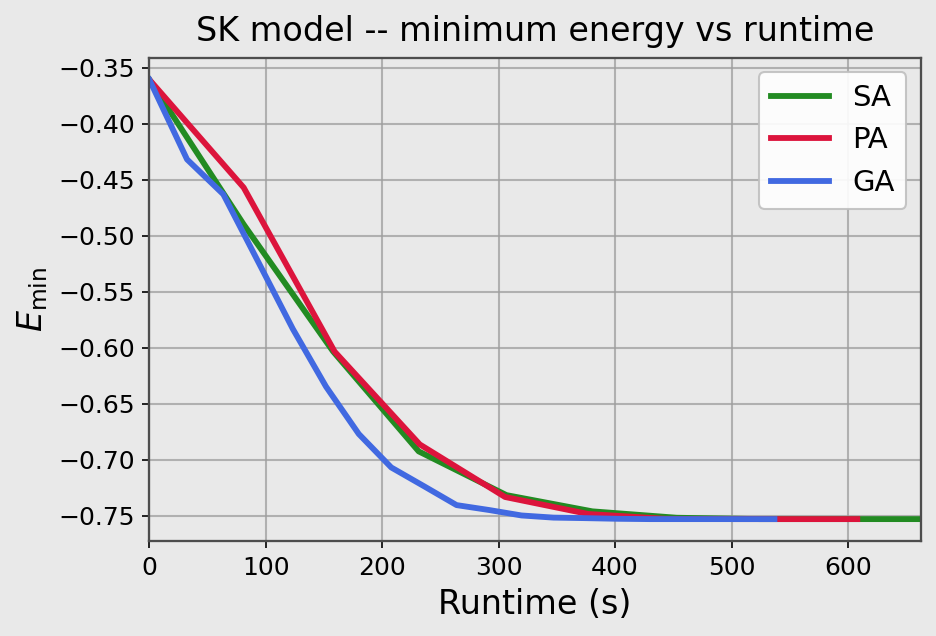

In [70]:
plot_energy_comparison(results_SA=results_SA, results_PA=results_PA, results_GA=results_GA, normalize_by_N=False)

## Results discussion:
The figure compares the evolution of the minimum energy per spin found by SA, PA, and GA for an Sherrington–Kirkpatrick instance with $N=512$ spins and a population size of 4096. All three algorithms progressively reach lower energy configurations and eventually converge to very similar final values, around $E_{min}/N\approx -0.75$

GA decreases the energy more rapidly during the intermediate part of the run and reaches the final low-energy region earlier than SA and PA. However, at longer runtimes, the differences between the three methods become small, and no clear advantage can yet be established from this single instance.

These results should be regarded as preliminary. No exact ground state reference is currently available, so the plotted quantity represents only the lowest energy found during each run. Consequently, reaching the same final energy does not guarantee that the true ground state has been identified. A reliable comparison will require multiple disorder instances, repeated independent runs, success probabilities, and either exact ground state energies or stronger best-known reference values.

# Conclusions

The implementation reproduces the main qualitative results of the reference study for the three dimensional Edwards–Anderson model. The numerical curves are not expected to match the paper point by point, but the characteristic behavior of the three algorithms is recovered.

SA reduces the energy efficiently at early times but eventually slows down and becomes trapped. PA performs very well on the studied EA instance and reaches the reference minimum earlier than GA. GA is initially slower because of the cost of training and evaluating MADE, but its global proposals allow it to continue exploring the energy landscape and eventually reach the same minimum. The unrestricted energy traces also suggest that PA can temporarily lose particularly good configurations, while GA tends to remain closer to favorable low energy regions once they are found.

The sampling analysis shows that finding low energy configurations does not automatically imply correct equilibrium sampling. PA and GA produce lower energy populations than SA, but the overlap distribution provides a clearer distinction. SA fails to reproduce the reference low temperature structure, while PA and the GA variants with global moves provide much better agreement. Global MADE proposals therefore improve the exploration compared with local moves alone.

Frequent retraining is not always advantageous. Retraining every 10 updates increases the acceptance rate of global proposals, but produces a less accurate overlap distribution than the frozen model or the longer retraining interval. This indicates that MADE may adapt too strongly to temporary biases in the current population. The acceptance rate must therefore be considered together with physical observables such as the energy and overlap distributions.

The extension to the fully connected SK model shows that the same annealing framework can be applied beyond the EA model. After replacing the couplings and the checkerboard update, all three algorithms reach almost the same final minimum energy on the tested instance. GA reaches the low energy plateau earlier, suggesting that learned global proposals remain useful even when the interaction structure is fully connected.

Overall, SA is the simplest method but has the clearest limitations at long times and as a sampler. PA is efficient and competitive, although resampling can reduce population diversity. GA results more computationally costly and depends on the quality of the learned proposal distribution, but it provides the most flexible mechanism for exploring distant regions of configuration space. Since the present comparisons use a limited number of disorder realizations and system sizes, broader tests are required before drawing general performance conclusions.